# Klasifikasi Uang Kertas Rupiah - EDA, Preprocessing, dan Custom CNN (7 Kelas)

**Cakupan tugas asistensi**
- **21 Oktober:** EDA, audit kualitas, split stratified 70/15/15, resize 224×224, pipeline augmentasi (hanya train), dan **baseline Custom CNN**.
- **28 Oktober:** tuning (epoch & augmentasi), perbandingan eksperimen, dan **evaluasi final test set**.

Sumber data: <https://github.com/mkaspulanwar/rupiah-banknotes-dataset>



## 1. Setup dan konfigurasi

Semua parameter penting ada di satu tempat (`Config`) supaya mudah diubah dan tercatat di laporan akhir.

In [ ]:
import os, sys, io, json, math, random, shutil, hashlib, platform, subprocess, time, warnings
from pathlib import Path
from dataclasses import dataclass, asdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

try:
    from tqdm.auto import tqdm
except ImportError:                       # tqdm tidak wajib
    def tqdm(x, **kw): return x

IN_COLAB = Path('/content').is_dir()
BASE_DIR = Path('/content') if IN_COLAB else Path('.')


@dataclass(frozen=True)
class Config:
    # --- data
    seed: int = 42
    classes: tuple = ('idr_1000', 'idr_2000', 'idr_5000', 'idr_10000',
                      'idr_20000', 'idr_50000', 'idr_100000')
    img_size: tuple = (224, 224)
    split_ratios: tuple = (0.70, 0.15, 0.15)   # train, val, test
    n_group_folds: int = 20                    # 1 fold = 5% data; 14/3/3 fold -> 70/15/15
    near_dup_threshold: int = 6                # jarak Hamming dHash (0-64); makin kecil makin ketat
    resize_mode: str = 'pad'                   # 'pad' = jaga proporsi + padding hitam | 'stretch'
    n_workers: int = min(8, os.cpu_count() or 2)
    # --- training
    batch_size: int = 32
    baseline_epochs: int = 15
    tuning_epochs: int = 30
    baseline_lr: float = 1e-3
    tuning_lr: float = 5e-4
    patience: int = 8
    # --- lokasi
    repo_url: str = 'https://github.com/mkaspulanwar/rupiah-banknotes-dataset.git'
    data_root_override: str = os.environ.get('RUPIAH_DATA_ROOT', '')
    quick_test: bool = os.environ.get('RUPIAH_QUICK', '') == '1'   # uji cepat: epoch minimal


cfg = Config()
CLASSES = list(cfg.classes)
IMG_SIZE = tuple(cfg.img_size)
SEED = cfg.seed
random.seed(SEED); np.random.seed(SEED)

OUT_ROOT = BASE_DIR / 'rupiah_processed'
REPORT_DIR = OUT_ROOT / 'eda_reports'
RESULTS = OUT_ROOT / 'training_results'
for d in (OUT_ROOT, REPORT_DIR, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25,
                     'axes.spines.top': False, 'axes.spines.right': False})


def pretty(c):
    """'idr_10000' -> 'Rp 10.000'"""
    return 'Rp ' + f"{int(c.split('_')[1]):,}".replace(',', '.')


print('Konfigurasi:')
for k, v in asdict(cfg).items():
    print(f'  {k:20s} {v}')
if cfg.quick_test:
    print('\n>>> MODE UJI CEPAT AKTIF: epoch dipangkas, hasil akurasi TIDAK valid untuk laporan.')

Konfigurasi:
  seed                 42
  classes              ('idr_1000', 'idr_2000', 'idr_5000', 'idr_10000', 'idr_20000', 'idr_50000', 'idr_100000')
  img_size             (224, 224)
  split_ratios         (0.7, 0.15, 0.15)
  n_group_folds        20
  near_dup_threshold   6
  resize_mode          pad
  n_workers            2
  batch_size           32
  baseline_epochs      15
  tuning_epochs        30
  baseline_lr          0.001
  tuning_lr            0.0005
  patience             8
  repo_url             https://github.com/mkaspulanwar/rupiah-banknotes-dataset.git
  data_root_override   
  quick_test           False


In [ ]:
# --- Cari / unduh dataset -------------------------------------------------------
def run(cmd):
    return subprocess.run(cmd, check=True, capture_output=True, text=True).stdout.strip()

if cfg.data_root_override:
    repo = Path(cfg.data_root_override)
else:
    repo = BASE_DIR / 'rupiah-banknotes-dataset'
    if not repo.exists():
        print('Meng-clone dataset (sekali saja)...')
        run(['git', 'clone', '--depth', '1', cfg.repo_url, str(repo)])
if not repo.exists():
    raise FileNotFoundError(f'Folder dataset tidak ditemukan: {repo}')

# Kelas bisa berada di root repo atau 1 tingkat di bawahnya (folder tersembunyi diabaikan)
candidates = [repo] + [d for d in repo.glob('*') if d.is_dir() and not d.name.startswith('.')] \
                    + [d for d in repo.glob('*/*') if d.is_dir() and not d.parent.name.startswith('.')]
DATA_ROOT = next((d for d in candidates if all((d / c).is_dir() for c in CLASSES)), None)
if DATA_ROOT is None:
    raise FileNotFoundError('Folder tujuh kelas tidak ditemukan. Periksa struktur folder dataset: '
                            + str(sorted(p.name for p in repo.iterdir())))

try:
    DATASET_COMMIT = run(['git', '-C', str(repo), 'rev-parse', 'HEAD'])
except Exception:
    DATASET_COMMIT = 'tidak diketahui'

IMG_EXT = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
excluded_dirs = {n: sum(1 for p in (DATA_ROOT / n).rglob('*') if p.suffix.lower() in IMG_EXT)
                 for n in ('idr_mix', 'test') if (DATA_ROOT / n).is_dir()}

print('DATA_ROOT      :', DATA_ROOT.resolve())
print('Commit dataset :', DATASET_COMMIT)
print('Output         :', OUT_ROOT.resolve())
print('Folder di luar 7 kelas (tidak dipakai):', excluded_dirs or 'tidak ada')
print(f'Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__}')

Meng-clone dataset (sekali saja)...
DATA_ROOT      : /content/rupiah-banknotes-dataset
Commit dataset : 8574bfae07c29ae60f572f0f17d3e23582d29649
Output         : /content/rupiah_processed
Folder di luar 7 kelas (tidak dipakai): {'idr_mix': 143, 'test': 0}
Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3


## 2. Inventaris dataset dan audit kualitas gambar



In [ ]:
def laplacian_variance(gray):
    """Variance of Laplacian (kernel 4-tetangga). Makin kecil -> makin blur."""
    g = gray.astype(np.float32)
    lap = -4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:]
    return float(lap.var())


def dhash64(gray_img):
    """Difference hash 64-bit dari gambar grayscale PIL."""
    a = np.asarray(gray_img.resize((9, 8), Image.Resampling.LANCZOS), dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    h = 0
    for b in bits:
        h = (h << 1) | int(b)
    return h


def analyze_image(item):
    path, cls = item
    rec = {'path': str(path), 'filename': path.name, 'label': cls, 'valid': False, 'error': None}
    try:
        data = path.read_bytes()
        sha = hashlib.sha256(data).hexdigest()
        with Image.open(io.BytesIO(data)) as im:
            fmt, mode0 = im.format, im.mode
            orientation = im.getexif().get(0x0112, 1)
            w, h = im.size
            if orientation in (5, 6, 7, 8):          # EXIF memutar 90 derajat
                w, h = h, w
            if w < 1 or h < 1:
                raise ValueError('Dimensi tidak valid')
            im.draft('RGB', (448, 448))               # JPEG: dekode skala kecil (jauh lebih cepat)
            rgb = ImageOps.exif_transpose(im).convert('RGB')
        gray = rgb.convert('L').resize(IMG_SIZE, Image.Resampling.BOX)
        g = np.asarray(gray, dtype=np.float32)
        rec.update(valid=True, width=w, height=h, mode=mode0, format=fmt,
                   aspect_ratio=w / h, file_kb=len(data) / 1024, sha256=sha,
                   brightness=float(g.mean()), contrast=float(g.std()),
                   blur_laplacian=laplacian_variance(g),
                   glare_ratio=float((g >= 250).mean()),
                   dhash=f'{dhash64(gray):016x}')
    except Exception as e:                            # berkas rusak apa pun jenisnya dicatat, bukan dihentikan
        rec['error'] = f'{type(e).__name__}: {e}'
    return rec


files = [(p, cls) for cls in CLASSES
         for p in sorted((DATA_ROOT / cls).rglob('*'))
         if p.is_file() and p.suffix.lower() in IMG_EXT]
if not files:
    raise RuntimeError('Tidak ada gambar ditemukan. Periksa isi folder dataset.')

t0 = time.time()
with ThreadPoolExecutor(cfg.n_workers) as ex:
    records = list(tqdm(ex.map(analyze_image, files), total=len(files), desc='Menganalisis gambar'))
inventory = pd.DataFrame(records)
valid = inventory[inventory.valid].copy().reset_index(drop=True)
valid[['width', 'height']] = valid[['width', 'height']].astype(int)
valid['orientation'] = np.where(valid.width >= valid.height, 'landscape', 'portrait')
print(f'Selesai dalam {time.time() - t0:.1f} detik')

Menganalisis gambar:   0%|          | 0/1249 [00:00<?, ?it/s]

Selesai dalam 68.7 detik


In [ ]:
n_bad = int((~inventory.valid).sum())
per_class = valid.label.value_counts().reindex(CLASSES, fill_value=0)
print(f'Total gambar ditemukan : {len(inventory)}')
print(f'Valid / tidak valid    : {len(valid)} / {n_bad}')
print(f'Rasio kelas terbesar/terkecil: {per_class.max() / per_class.min():.2f}')

print('\nJumlah per kelas:')
display(per_class.rename('jumlah').to_frame().assign(persen=lambda d: (d.jumlah / d.jumlah.sum() * 100).round(1)))

print('Ringkasan resolusi, ukuran berkas, dan mode warna:')
display(valid[['width', 'height', 'aspect_ratio', 'file_kb']].describe().round(2))
print('Mode warna :', valid['mode'].value_counts().to_dict())
print('Format     :', valid['format'].value_counts().to_dict())
print('\nOrientasi per kelas (setelah koreksi EXIF):')
display(pd.crosstab(valid.label, valid.orientation).reindex(CLASSES))

if n_bad:
    print('\nBerkas bermasalah:')
    display(inventory.loc[~inventory.valid, ['path', 'error']])

Total gambar ditemukan : 1249
Valid / tidak valid    : 1249 / 0
Rasio kelas terbesar/terkecil: 1.29

Jumlah per kelas:


,jumlah,persen
label,,
idr_1000,166,13.3
idr_2000,178,14.3
idr_5000,167,13.4
idr_10000,156,12.5
idr_20000,189,15.1
idr_50000,202,16.2
idr_100000,191,15.3


Ringkasan resolusi, ukuran berkas, dan mode warna:


,width,height,aspect_ratio,file_kb
count,1249.00,1249.00,1249.00,1249.00
mean,4009.40,3127.10,1.29,2747.94
std,258.15,257.73,0.15,496.68
min,3060.00,2448.00,0.75,1414.73
25%,4080.00,3060.00,1.33,2358.45
50%,4080.00,3060.00,1.33,2787.86
75%,4080.00,3060.00,1.33,3099.51
max,4080.00,4080.00,1.33,4546.39


Mode warna : {'RGB': 1249}
Format     : {'JPEG': 1249}

Orientasi per kelas (setelah koreksi EXIF):


orientation,landscape,portrait
label,,
idr_1000,162,4
idr_2000,163,15
idr_5000,127,40
idr_10000,131,25
idr_20000,189,0
idr_50000,202,0
idr_100000,191,0


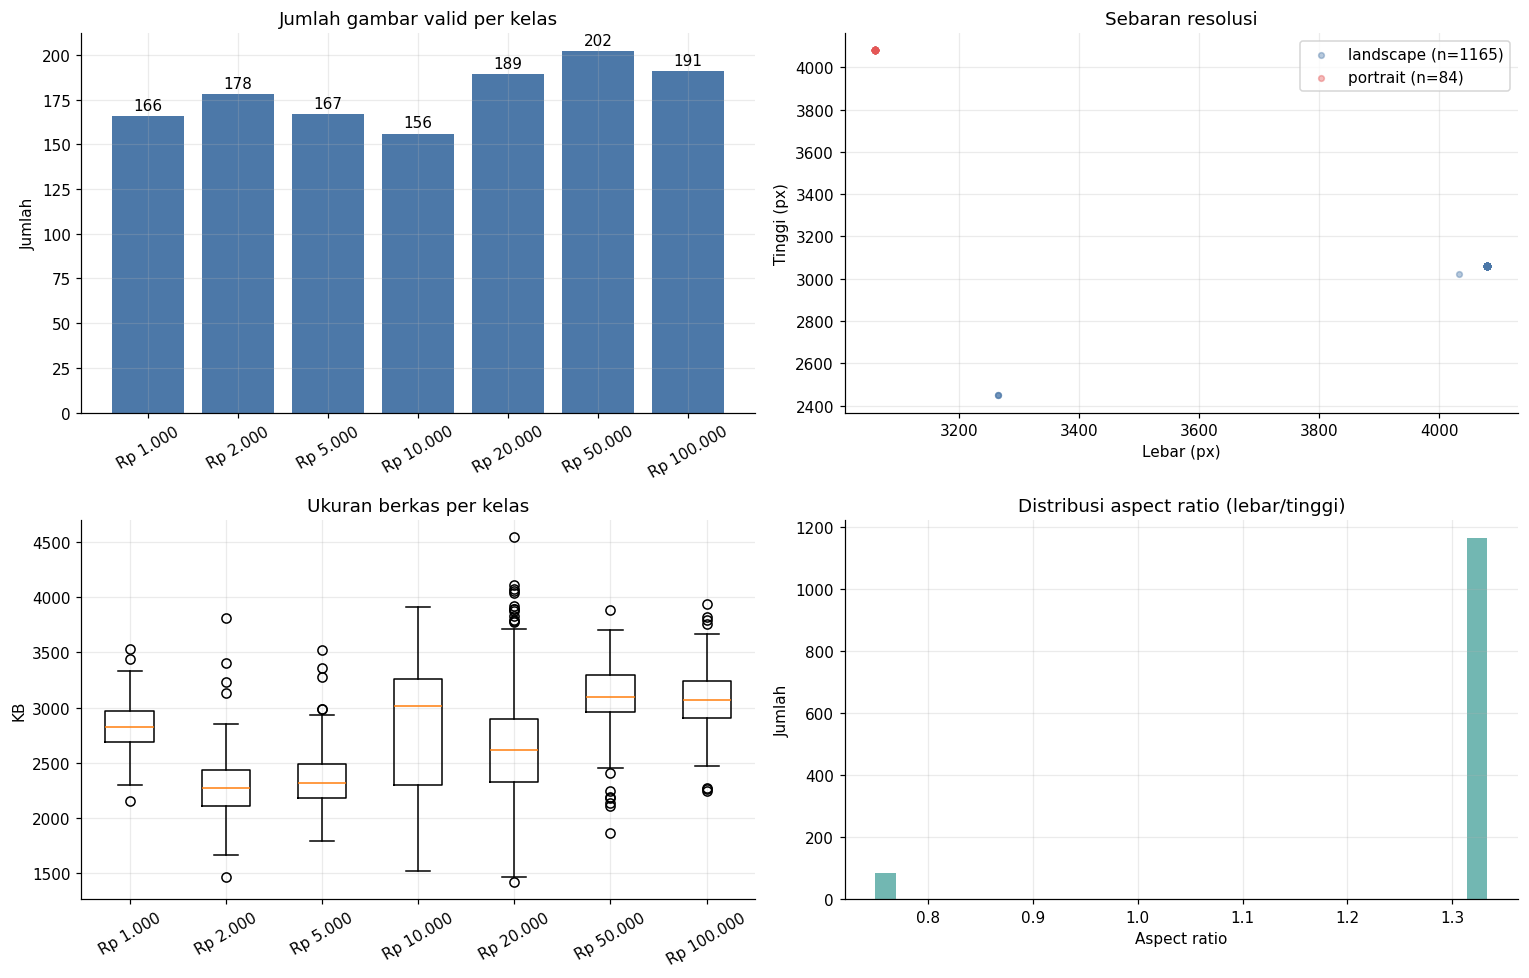

In [ ]:
def labeled_boxplot(ax, data, labels):
    ax.boxplot(data)
    ax.set_xticks(range(1, len(labels) + 1))
    ax.set_xticklabels(labels)


fig, axes = plt.subplots(2, 2, figsize=(14, 9))

ax = axes[0, 0]
bars = ax.bar([pretty(c) for c in CLASSES], per_class.values, color='#4C78A8')
ax.bar_label(bars, padding=2)
ax.set(title='Jumlah gambar valid per kelas', ylabel='Jumlah')
ax.tick_params(axis='x', rotation=30)

ax = axes[0, 1]
for ori, color in (('landscape', '#4C78A8'), ('portrait', '#E45756')):
    s = valid[valid.orientation == ori]
    ax.scatter(s.width, s.height, alpha=.4, s=14, label=f'{ori} (n={len(s)})', color=color)
ax.set(title='Sebaran resolusi', xlabel='Lebar (px)', ylabel='Tinggi (px)')
ax.legend()

ax = axes[1, 0]
labeled_boxplot(ax, [valid.loc[valid.label == c, 'file_kb'] for c in CLASSES], [pretty(c) for c in CLASSES])
ax.set(title='Ukuran berkas per kelas', ylabel='KB')
ax.tick_params(axis='x', rotation=30)

ax = axes[1, 1]
ax.hist(valid.aspect_ratio, bins=30, color='#72B7B2')
ax.set(title='Distribusi aspect ratio (lebar/tinggi)', xlabel='Aspect ratio', ylabel='Jumlah')

plt.tight_layout(); plt.show()

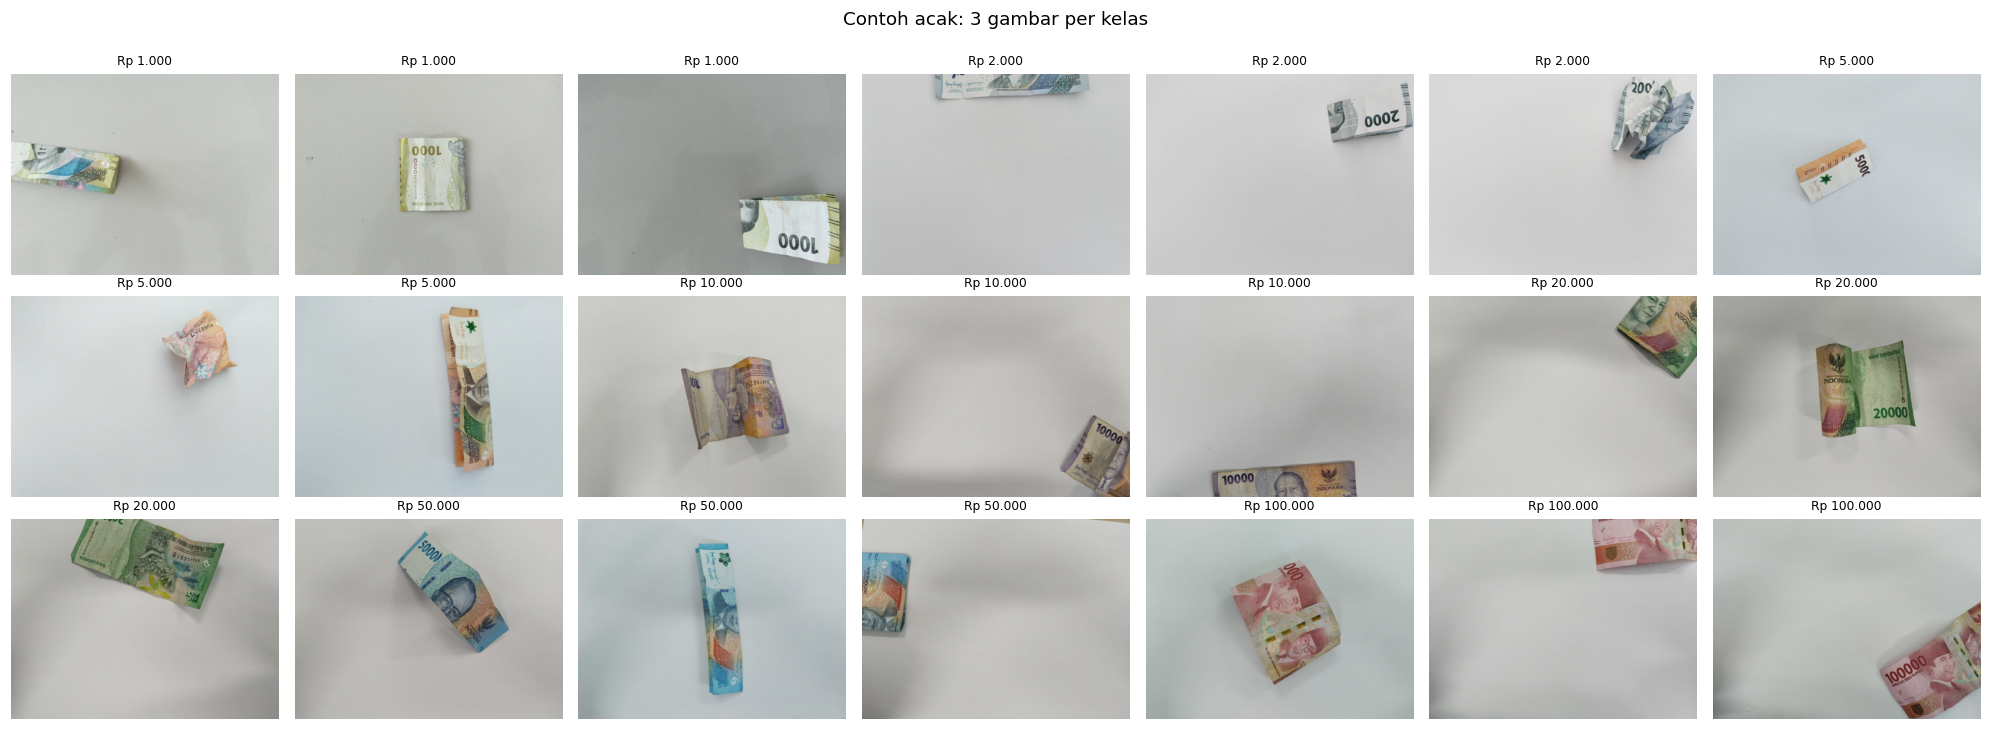

In [ ]:
def load_thumb(path, max_side=480):
    """Buka gambar besar dengan cepat (JPEG draft) lalu perkecil untuk ditampilkan."""
    with Image.open(path) as im:
        im.draft('RGB', (max_side, max_side))
        img = ImageOps.exif_transpose(im).convert('RGB')
    img.thumbnail((max_side, max_side))
    return img


def show_gallery(paths, titles=None, ncols=4, cell=3.2, suptitle=None, thumb=480):
    n = len(paths)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(cell * ncols, cell * 0.85 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for i, (ax, p) in enumerate(zip(axes.flat, paths)):
        ax.imshow(load_thumb(p, thumb))
        ax.set_title(titles[i] if titles else Path(p).name, fontsize=8)
    if suptitle:
        fig.suptitle(suptitle, y=1.0)
    plt.tight_layout(); plt.show()


# 3 contoh acak per kelas (seed tetap) supaya variasi pose/latar terlihat
rng = np.random.default_rng(SEED)
sample_rows = []
for c in CLASSES:
    sub = valid[valid.label == c]
    sample_rows += list(sub.iloc[rng.choice(len(sub), size=min(3, len(sub)), replace=False)].itertuples())
show_gallery([r.path for r in sample_rows], [pretty(r.label) for r in sample_rows],
             ncols=7, cell=2.6, suptitle='Contoh acak: 3 gambar per kelas')

### 2.1 Audit kualitas

Gambar ditandai (*flag*) jika nilainya ekstrem menurut aturan IQR (Q1 − 1.5·IQR atau Q3 + 1.5·IQR) terhadap seluruh dataset. Tanda ini hanya mengarahkan **inspeksi visual**.

Median metrik kualitas per kelas:


,brightness,contrast,blur_laplacian,glare_ratio,file_kb
label,,,,,
idr_1000,185.747,15.899,221.645,0.0,2821.219
idr_2000,201.098,18.848,234.596,0.0,2266.309
idr_5000,199.219,18.544,205.627,0.0,2318.049
idr_10000,180.050,22.695,163.209,0.0,3016.613
idr_20000,173.212,25.071,225.104,0.0,2614.580
idr_50000,177.934,22.717,193.582,0.0,3097.529
idr_100000,179.736,21.977,162.787,0.0,3067.891


Jumlah gambar yang ditandai:


,flag_blur,flag_dark,flag_bright,flag_low_contrast,flag_glare
jumlah,9,1,1,1,0


Gambar dengan >=1 tanda: 12 dari 1249 (1.0%)


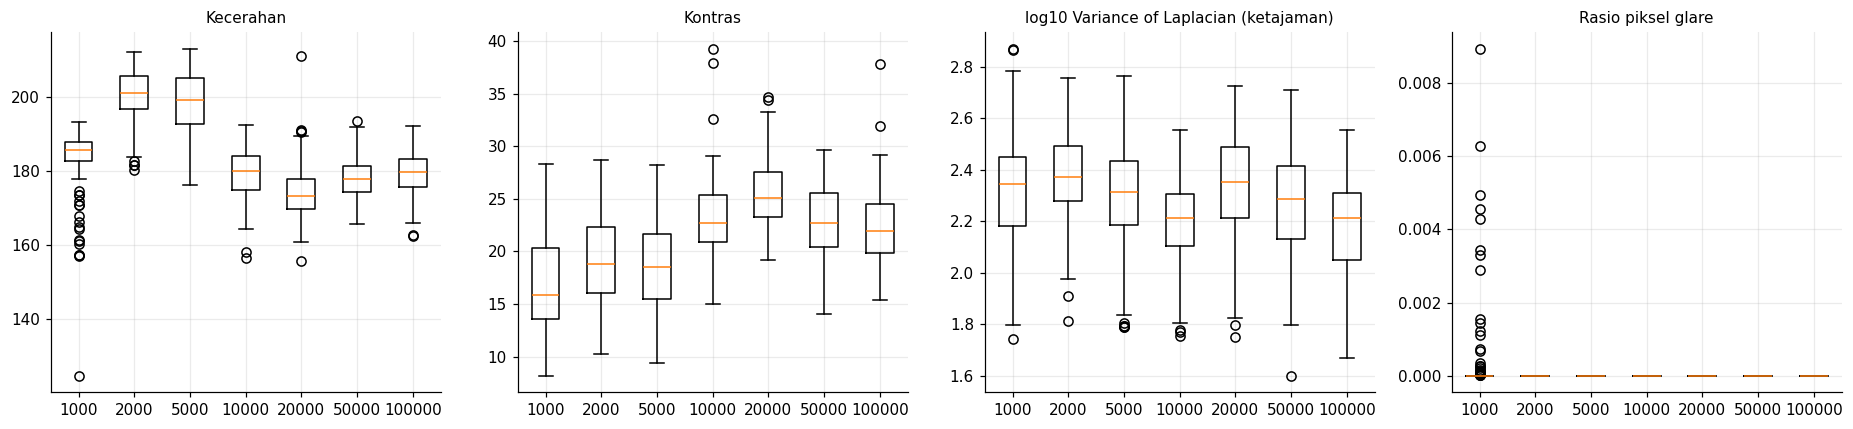

In [ ]:
q = valid.copy()
q['log_blur'] = np.log10(q.blur_laplacian + 1e-6)

def iqr_fence(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

blur_lo, _ = iqr_fence(q.log_blur)
bright_lo, bright_hi = iqr_fence(q.brightness)
contrast_lo, _ = iqr_fence(q.contrast)
_, glare_hi = iqr_fence(q.glare_ratio)

q['flag_blur'] = q.log_blur < blur_lo
q['flag_dark'] = q.brightness < bright_lo
q['flag_bright'] = q.brightness > bright_hi
q['flag_low_contrast'] = q.contrast < contrast_lo
q['flag_glare'] = q.glare_ratio > max(0.02, glare_hi)
flag_cols = [c for c in q.columns if c.startswith('flag_')]
q['n_flags'] = q[flag_cols].sum(axis=1)

print('Median metrik kualitas per kelas:')
display(q.groupby('label')[['brightness', 'contrast', 'blur_laplacian', 'glare_ratio', 'file_kb']]
        .median().reindex(CLASSES).round(3))
print('Jumlah gambar yang ditandai:')
display(q[flag_cols].sum().rename('jumlah').to_frame().T)
print(f'Gambar dengan >=1 tanda: {(q.n_flags > 0).sum()} dari {len(q)} ({(q.n_flags > 0).mean():.1%})')

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, col, title in zip(axes, ['brightness', 'contrast', 'log_blur', 'glare_ratio'],
                          ['Kecerahan', 'Kontras', 'log10 Variance of Laplacian (ketajaman)', 'Rasio piksel glare']):
    labeled_boxplot(ax, [q.loc[q.label == c, col] for c in CLASSES], [c.replace('idr_', '') for c in CLASSES])
    ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.show()

,label,filename,blur_laplacian,brightness,contrast,glare_ratio,n_flags
905,idr_50000,IMG_20240527_160643.jpg,39.765,182.129,17.538,0.0,1
1158,idr_100000,IMG_20240527_164147.jpg,46.778,175.036,16.852,0.0,1
1173,idr_100000,IMG_20240527_164313.jpg,53.581,182.733,20.818,0.0,1
71,idr_1000,IMG_20240527_115433.jpg,55.349,184.027,8.857,0.0,1
734,idr_20000,IMG_20240527_153513.jpg,56.517,183.621,23.550,0.0,1
625,idr_10000,IMG_20240527_151030.jpg,57.034,184.045,16.896,0.0,1
1128,idr_100000,IMG_20240527_163828.jpg,58.626,182.061,20.052,0.0,1
548,idr_10000,IMG_20240527_145922.jpg,58.766,179.816,19.759,0.0,1
550,idr_10000,IMG_20240527_145930.jpg,59.974,180.158,20.121,0.0,1
81,idr_1000,IMG_20240527_115807.jpg,91.124,185.600,8.169,0.0,1


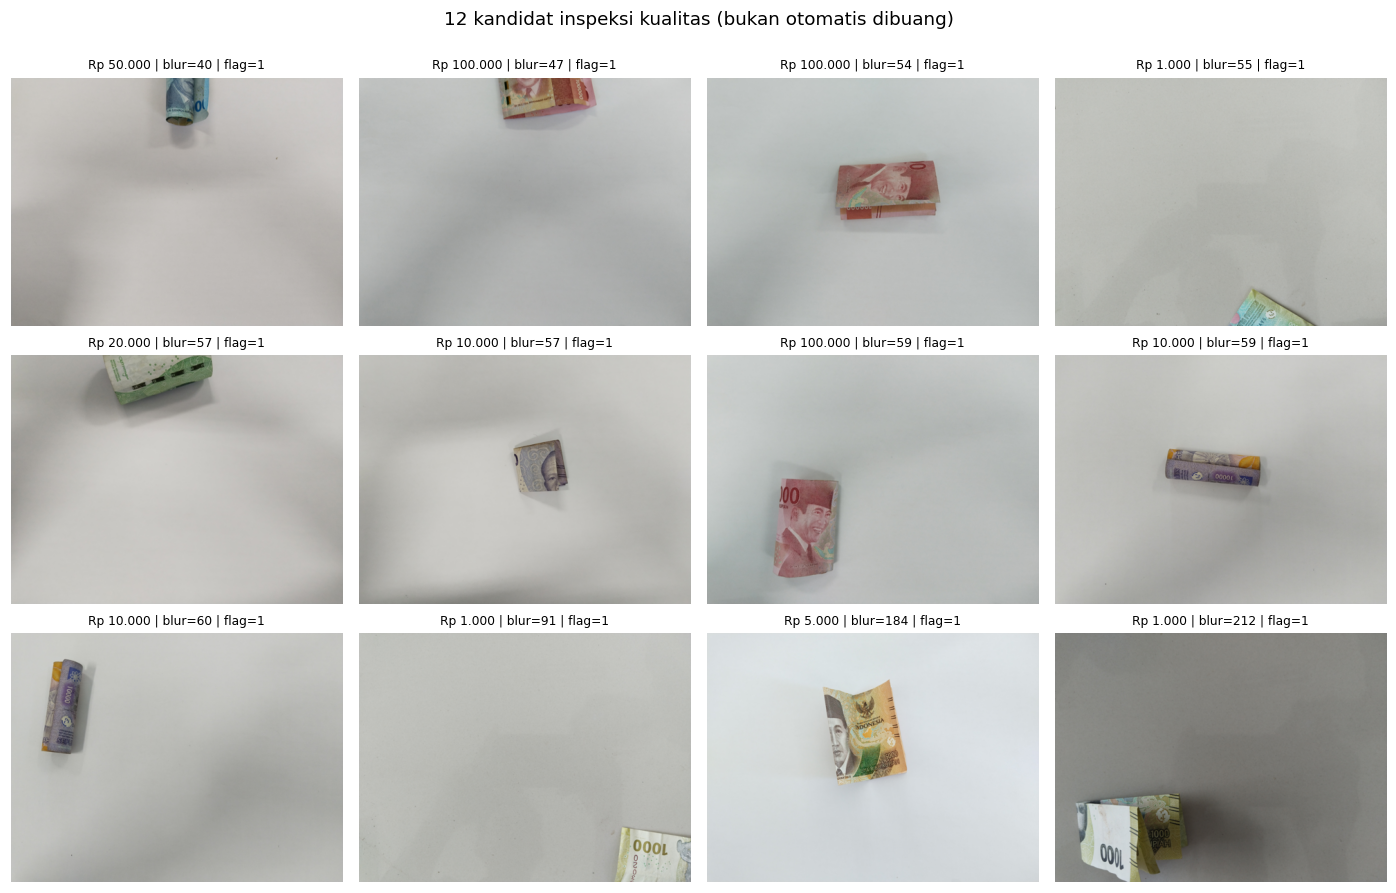

In [ ]:
# Kandidat inspeksi: jumlah tanda terbanyak, lalu paling blur
review = q.sort_values(['n_flags', 'blur_laplacian'], ascending=[False, True]).head(12)
display(review[['label', 'filename', 'blur_laplacian', 'brightness', 'contrast', 'glare_ratio', 'n_flags']].round(3))
show_gallery(review.path.tolist(),
             [f'{pretty(r.label)} | blur={r.blur_laplacian:.0f} | flag={r.n_flags}' for r in review.itertuples()],
             ncols=4, suptitle='12 kandidat inspeksi kualitas (bukan otomatis dibuang)')

## 3. Duplikat dan kebocoran data


In [ ]:
# --- 3.1 Duplikat persis ---------------------------------------------------------
hash_nlabels = valid.groupby('sha256').label.nunique()
conflict_hashes = set(hash_nlabels[hash_nlabels > 1].index)
is_conflict = valid.sha256.isin(conflict_hashes)
is_exact_copy = valid.duplicated('sha256', keep='first') & ~is_conflict

excluded = pd.concat([
    valid[is_conflict].assign(reason='label_konflik'),
    valid[is_exact_copy].assign(reason='duplikat_persis'),
])[['path', 'label', 'sha256', 'reason']]
clean = valid[~is_conflict & ~is_exact_copy].reset_index(drop=True)

print(f'Berkas dengan hash duplikat (termasuk salinan pertama): {valid.duplicated("sha256", keep=False).sum()}')
print(f'Kelompok hash dengan label konflik                    : {len(conflict_hashes)}')
print(f'Dikeluarkan: {len(excluded)} | Gambar unik tersisa: {len(clean)}')
if len(excluded):
    display(excluded.head(20))
excluded.to_csv(REPORT_DIR / 'excluded_files.csv', index=False)

Berkas dengan hash duplikat (termasuk salinan pertama): 0
Kelompok hash dengan label konflik                    : 0
Dikeluarkan: 0 | Gambar unik tersisa: 1249


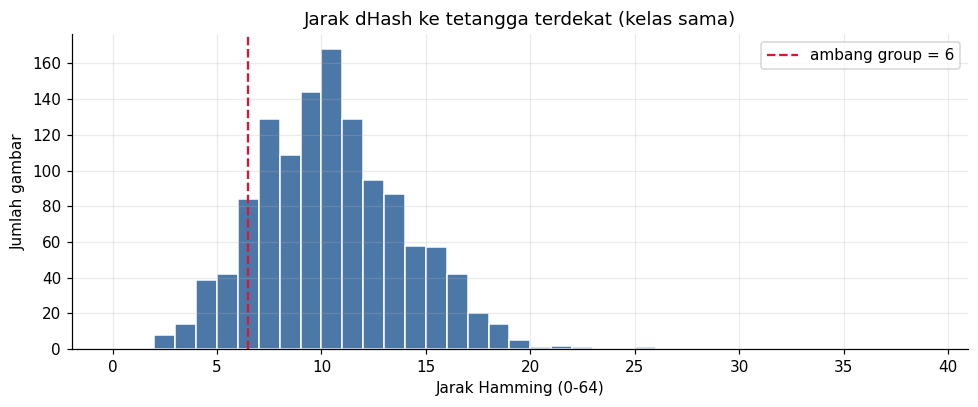

Jumlah group                         : 1126 (dari 1249 gambar)
Group berisi >1 gambar               : 64 (mencakup 187 gambar, 15.0%)
Ukuran group terbesar                : 14
Pasangan BEDA kelas dengan jarak <= 6: 12  (potensi label konflik / latar mirip, tinjau manual)


In [ ]:
# --- 3.2 Near-duplicate dengan jarak Hamming dHash --------------------------------
POP8 = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

def hamming_matrix(h):
    """Matriks jarak Hamming (n x n) untuk array uint64."""
    x = np.bitwise_xor(h[:, None], h[None, :])
    return POP8[x.view(np.uint8).reshape(len(h), len(h), 8)].sum(axis=2, dtype=np.int16)

h = np.array([int(x, 16) for x in clean.dhash], dtype=np.uint64)
D = hamming_matrix(h)
lab = clean.label.to_numpy(dtype=object)
cross_label = lab[:, None] != lab[None, :]
same_label = ~cross_label
np.fill_diagonal(same_label, False)

D_same = np.where(same_label, D, 65)                       # hanya pasangan sama-kelas
D_cross = np.where(cross_label, D, 65)                     # hanya pasangan beda kelas
nn_dist = D_same.min(axis=1)                               # tetangga terdekat dalam kelas yang sama

THR = cfg.near_dup_threshold
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(nn_dist, bins=np.arange(0, 40), color='#4C78A8', edgecolor='white')
ax.axvline(THR + .5, color='crimson', ls='--', label=f'ambang group = {THR}')
ax.set(title='Jarak dHash ke tetangga terdekat (kelas sama)', xlabel='Jarak Hamming (0-64)', ylabel='Jumlah gambar')
ax.legend(); plt.tight_layout(); plt.show()

# Group = komponen terhubung dari pasangan sama-kelas dengan jarak <= ambang
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
n_groups, group_id = connected_components(csr_matrix(D_same <= THR), directed=False)
clean['group_id'] = group_id
sizes = clean.group_id.value_counts()
in_multi = int(sizes[sizes > 1].sum())

print(f'Jumlah group                         : {n_groups} (dari {len(clean)} gambar)')
print(f'Group berisi >1 gambar               : {(sizes > 1).sum()} (mencakup {in_multi} gambar, {in_multi / len(clean):.1%})')
print(f'Ukuran group terbesar                : {sizes.max()}')
n_cross = int(np.triu(D_cross <= THR, k=1).sum())
print(f'Pasangan BEDA kelas dengan jarak <= {THR}: {n_cross}  (potensi label konflik / latar mirip, tinjau manual)')
if sizes.max() > 0.05 * len(clean):
    print('PERINGATAN: ada group sangat besar. Ambang terlalu longgar; turunkan cfg.near_dup_threshold.')

clean[['path', 'label', 'sha256', 'dhash', 'group_id']].to_csv(REPORT_DIR / 'near_duplicate_groups.csv', index=False)

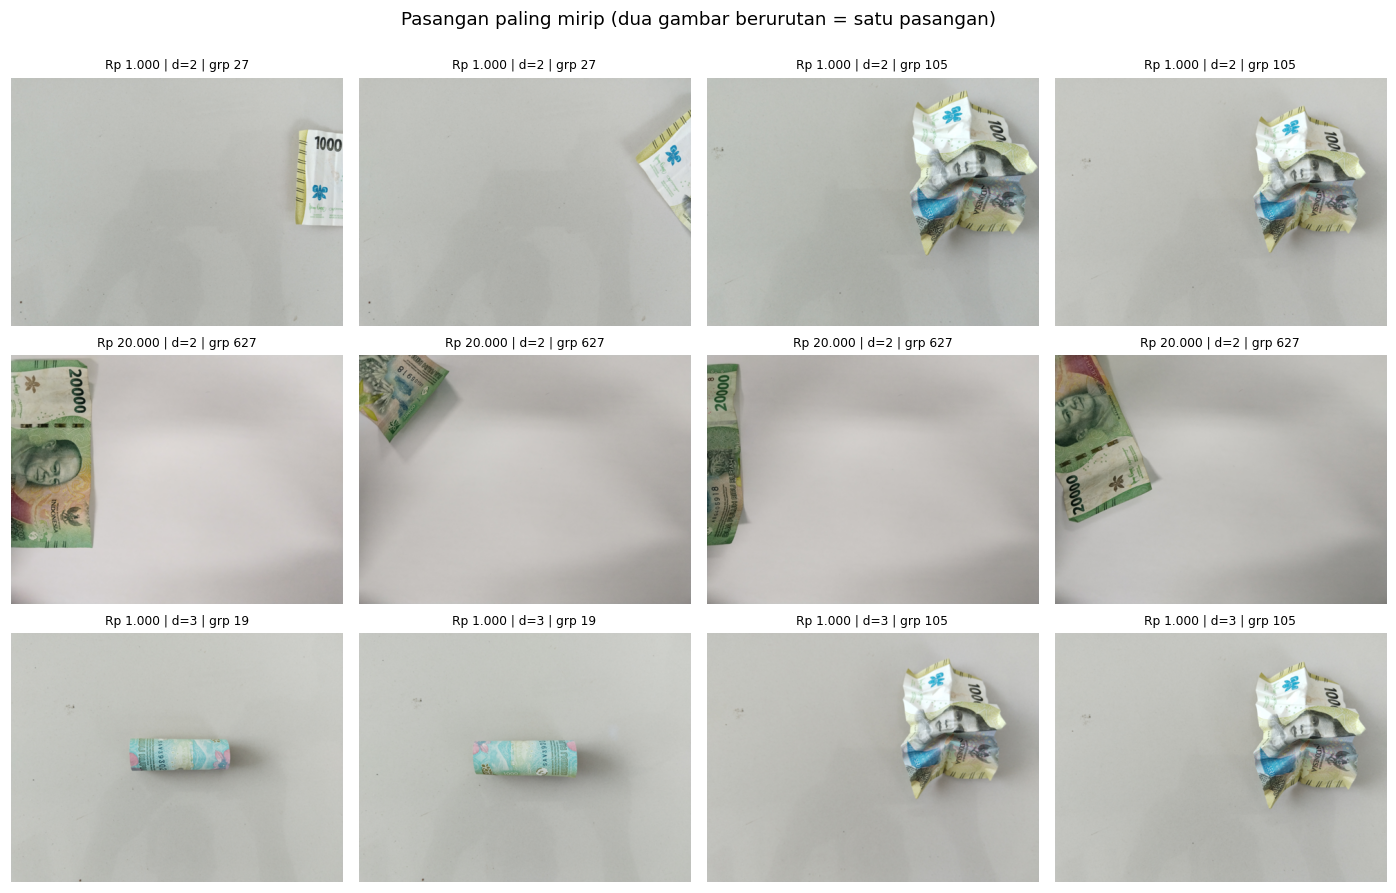

In [ ]:
# Galeri pasangan sama-kelas dengan jarak terkecil, untuk menilai apakah ambang masuk akal
pairs = np.argwhere(np.triu(D_same <= max(THR, 10), k=1))
pairs = sorted(pairs.tolist(), key=lambda ij: D_same[ij[0], ij[1]])[:6]
if pairs:
    paths, titles = [], []
    for i, j in pairs:
        for k in (i, j):
            paths.append(clean.path[k])
            titles.append(f'{pretty(clean.label[k])} | d={D_same[i, j]} | grp {clean.group_id[k]}')
    show_gallery(paths, titles, ncols=4, suptitle='Pasangan paling mirip (dua gambar berurutan = satu pasangan)')
else:
    print('Tidak ada pasangan dengan jarak kecil: foto tampak beragam menurut dHash.')

## 4. Split stratified dan group-aware (70/15/15)

`StratifiedGroupKFold` dengan 20 fold (masing-masing ±5% data): 14 fold untuk **train**, 3 untuk **validation**, 3 untuk **test**. Dengan cara ini:


OK: tidak ada group near-duplicate maupun hash identik lintas split

Jumlah gambar per kelas dan split:


split,train,val,test,total
label,,,,
idr_1000,130,15,21,166
idr_2000,127,27,24,178
idr_5000,111,26,30,167
idr_10000,111,22,23,156
idr_20000,135,29,25,189
idr_50000,149,27,26,202
idr_100000,131,30,30,191


Proporsi split aktual (target 70/15/15):
split
train    71.6
val      14.1
test     14.3

Proporsi tiap kelas di dalam split (%):


label,idr_1000,idr_2000,idr_5000,idr_10000,idr_20000,idr_50000,idr_100000
split,,,,,,,
train,14.5,14.2,12.4,12.4,15.1,16.7,14.7
val,8.5,15.3,14.8,12.5,16.5,15.3,17.0
test,11.7,13.4,16.8,12.8,14.0,14.5,16.8


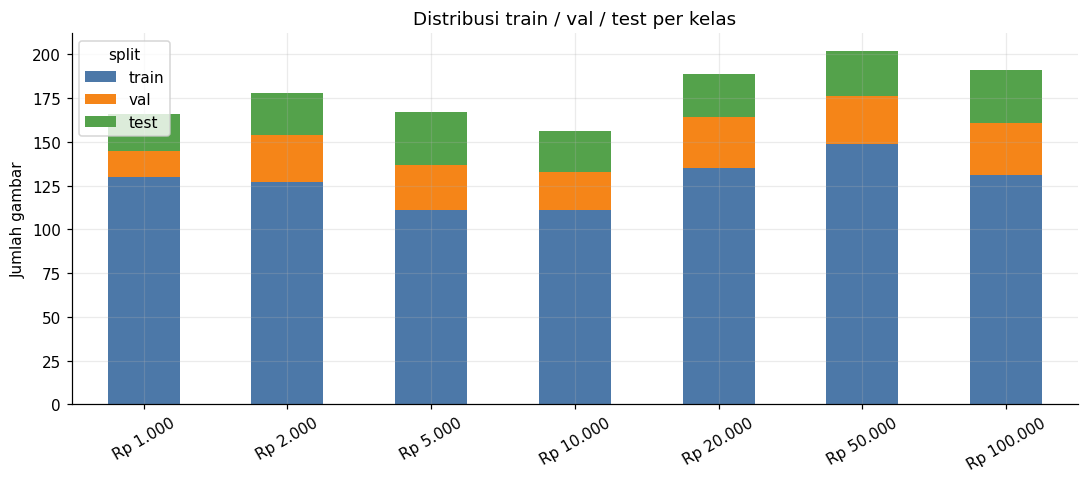

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

def grouped_stratified_split(frame, ratios, n_folds, seed):
    fold_counts = [r * n_folds for r in ratios]
    if any(abs(c - round(c)) > 1e-6 for c in fold_counts):
        raise ValueError(f'Rasio {ratios} tidak kompatibel dengan n_group_folds={n_folds}.')
    n_tr, n_va, _ = (round(c) for c in fold_counts)
    min_cls = frame.label.value_counts().min()
    if min_cls < n_folds:
        raise ValueError(f'Kelas terkecil hanya {min_cls} gambar unik (< {n_folds} fold). Tinjau data atau kurangi n_group_folds.')
    sgkf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    fold = np.empty(len(frame), dtype=int)
    for k, (_, idx) in enumerate(sgkf.split(frame, frame.label, frame.group_id)):
        fold[idx] = k
    return np.where(fold < n_tr, 'train', np.where(fold < n_tr + n_va, 'val', 'test'))

split_df = clean.copy()
split_df['split'] = grouped_stratified_split(split_df, cfg.split_ratios, cfg.n_group_folds, SEED)

# --- Verifikasi anti-kebocoran ---
assert (split_df.groupby('group_id').split.nunique() == 1).all(), 'Ada group yang terpecah antar split!'
sets = {s: set(split_df.loc[split_df.split == s, 'sha256']) for s in ('train', 'val', 'test')}
assert not (sets['train'] & sets['val'] or sets['train'] & sets['test'] or sets['val'] & sets['test'])
print('OK: tidak ada group near-duplicate maupun hash identik lintas split')

counts = pd.crosstab(split_df.label, split_df.split).reindex(CLASSES)[['train', 'val', 'test']]
counts['total'] = counts.sum(axis=1)
print('\nJumlah gambar per kelas dan split:')
display(counts)
print('Proporsi split aktual (target 70/15/15):')
print((split_df.split.value_counts(normalize=True).reindex(['train', 'val', 'test']) * 100).round(1).to_string())
print('\nProporsi tiap kelas di dalam split (%):')
display((pd.crosstab(split_df.split, split_df.label, normalize='index') * 100).reindex(['train', 'val', 'test'])[CLASSES].round(1))

fig, ax = plt.subplots(figsize=(10, 4.5))
counts[['train', 'val', 'test']].set_axis([pretty(c) for c in CLASSES]).plot(kind='bar', stacked=True, ax=ax,
                                                                           color=['#4C78A8', '#F58518', '#54A24B'])
ax.set(title='Distribusi train / val / test per kelas', ylabel='Jumlah gambar')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); fig.savefig(REPORT_DIR / 'split_distribution.png', dpi=160); plt.show()

## 5. Resize 224×224


In [ ]:
def preprocess_image(src, dst, size=IMG_SIZE, mode=cfg.resize_mode):
    with Image.open(src) as im:
        im.draft('RGB', (size[0] * 2, size[1] * 2))          # dekode cepat, tetap >= 2x ukuran target
        img = ImageOps.exif_transpose(im).convert('RGB')
    if mode == 'pad':
        resized = ImageOps.contain(img, size, method=Image.Resampling.LANCZOS)
        out = Image.new('RGB', size, (0, 0, 0))
        out.paste(resized, ((size[0] - resized.width) // 2, (size[1] - resized.height) // 2))
    elif mode == 'stretch':
        out = img.resize(size, Image.Resampling.LANCZOS)
    else:
        raise ValueError(f'resize_mode tidak dikenal: {mode}')
    dst.parent.mkdir(parents=True, exist_ok=True)
    out.save(dst, format='JPEG', quality=95)


# Hapus hasil run sebelumnya agar tidak tersisa file lama
for s in ('train', 'val', 'test'):
    if (OUT_ROOT / s).exists():
        shutil.rmtree(OUT_ROOT / s)

split_df = split_df.reset_index(drop=True)
split_df['processed_path'] = [
    str(OUT_ROOT / r.split / r.label / f'{i:05d}_{r.sha256[:10]}.jpg') for i, r in enumerate(split_df.itertuples())]

jobs = list(zip(split_df.path, map(Path, split_df.processed_path)))
t0 = time.time()
with ThreadPoolExecutor(cfg.n_workers) as ex:
    list(tqdm(ex.map(lambda a: preprocess_image(*a), jobs), total=len(jobs), desc='Resize'))
print(f'Selesai dalam {time.time() - t0:.1f} detik')

Resize:   0%|          | 0/1249 [00:00<?, ?it/s]

Selesai dalam 59.8 detik


Validasi preprocessing OK: 1249 gambar, semuanya (224, 224) RGB


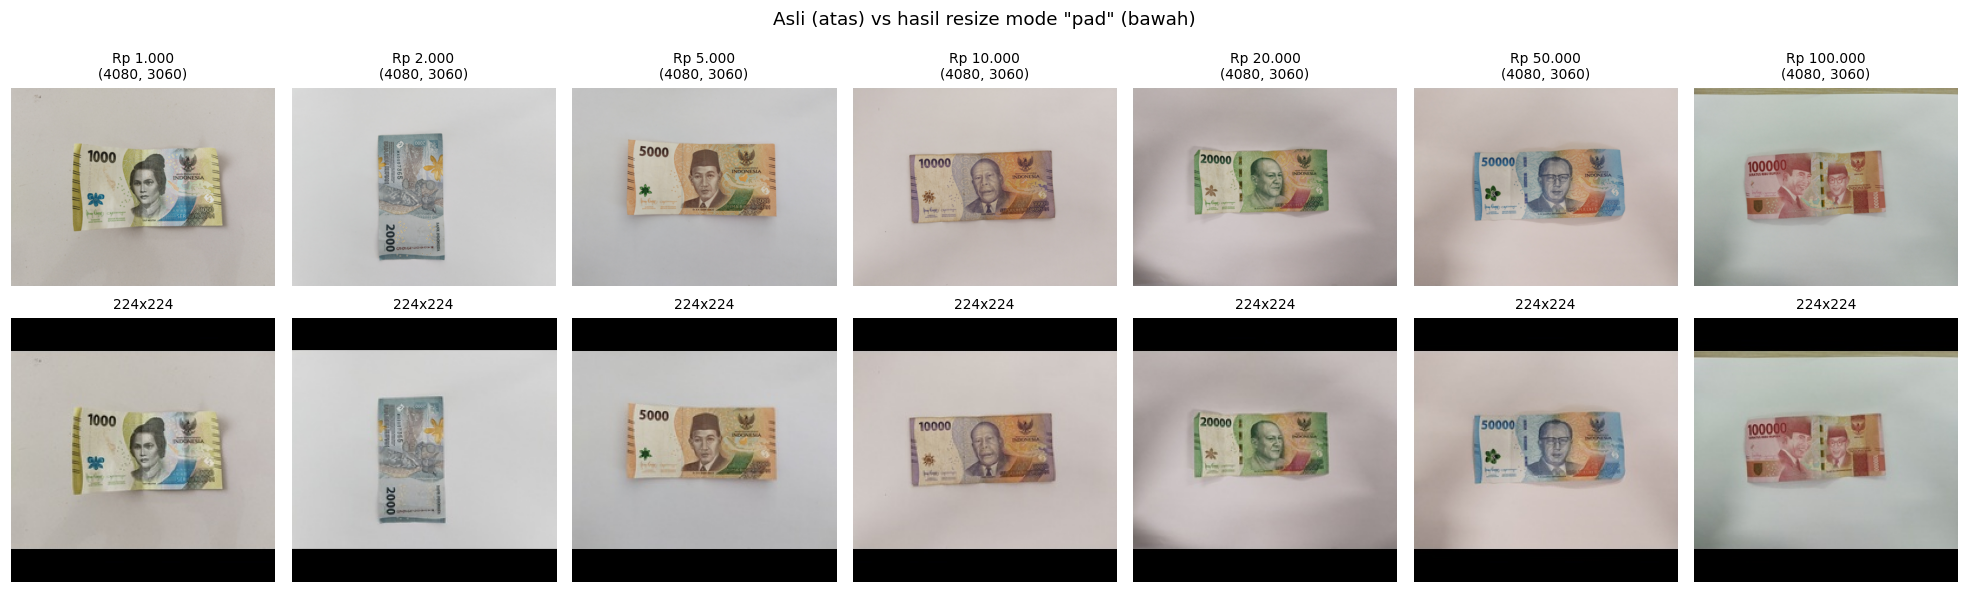

In [ ]:
# --- Validasi hasil preprocessing --------------------------------------------------
def check_processed(p):
    with Image.open(p) as im:
        return im.size, im.mode

with ThreadPoolExecutor(cfg.n_workers) as ex:
    info = list(ex.map(check_processed, split_df.processed_path))
assert all(s == IMG_SIZE for s, _ in info), 'Ada gambar bukan 224x224'
assert all(m == 'RGB' for _, m in info), 'Ada gambar bukan RGB'
for s in ('train', 'val', 'test'):
    n_disk = sum(1 for _ in (OUT_ROOT / s).rglob('*.jpg'))
    assert n_disk == (split_df.split == s).sum(), f'Jumlah berkas {s} tidak cocok'
print(f'Validasi preprocessing OK: {len(info)} gambar, semuanya {IMG_SIZE} RGB')

# --- Simpan manifest & inventaris --------------------------------------------------
inventory.to_csv(REPORT_DIR / 'eda_image_inventory.csv', index=False)
q.drop(columns=['dhash']).to_csv(REPORT_DIR / 'image_quality_metrics.csv', index=False)
split_df[['path', 'processed_path', 'label', 'sha256', 'group_id', 'split']].to_csv(OUT_ROOT / 'split_manifest.csv', index=False)
counts.to_csv(REPORT_DIR / 'split_summary.csv')
(OUT_ROOT / 'class_mapping.json').write_text(json.dumps({i: c for i, c in enumerate(CLASSES)}, indent=2), encoding='utf-8')

# --- Perbandingan asli vs hasil ----------------------------------------------------
fig, axes = plt.subplots(2, 7, figsize=(18, 5.5))
for j, c in enumerate(CLASSES):
    r = split_df[(split_df.label == c) & (split_df.split == 'train')].iloc[0]
    axes[0, j].imshow(load_thumb(r.path, 400)); axes[0, j].set_title(f'{pretty(c)}\n{Image.open(r.path).size}', fontsize=9)
    axes[1, j].imshow(Image.open(r.processed_path)); axes[1, j].set_title('224x224', fontsize=9)
    axes[0, j].axis('off'); axes[1, j].axis('off')
fig.suptitle(f'Asli (atas) vs hasil resize mode "{cfg.resize_mode}" (bawah)')
plt.tight_layout(); plt.show()

## 6. Pipeline `tf.data` dan augmentasi



In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, regularizers

tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
print('TensorFlow:', tf.__version__)
print('GPU       :', [g.name for g in tf.config.list_physical_devices('GPU')] or 'tidak ada (CPU; training akan lambat)')


def make_ds(split, training):
    raw = tf.keras.utils.image_dataset_from_directory(
        str(OUT_ROOT / split), labels='inferred', label_mode='int', class_names=CLASSES,
        image_size=IMG_SIZE, batch_size=None, shuffle=False)
    paths = list(raw.file_paths)
    ds = raw.cache()
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(cfg.batch_size).prefetch(AUTOTUNE), paths


train_ds, train_paths = make_ds('train', True)
val_ds, val_paths = make_ds('val', False)
test_ds, test_paths = make_ds('test', False)

# Sanity check: label dari Keras harus cocok dengan nama folder pada file_paths
for name, ds, paths in (('val', val_ds, val_paths), ('test', test_ds, test_paths)):
    y = np.concatenate([b.numpy() for _, b in ds])
    assert len(y) == len(paths) and all(CLASSES[k] == Path(p).parent.name for k, p in zip(y, paths)), f'Label {name} tidak selaras'
print('OK: label dan daftar berkas val/test selaras')

# --- Class weight: hanya dipakai bila ketidakseimbangan cukup besar ---
train_counts = split_df[split_df.split == 'train'].label.value_counts().reindex(CLASSES)
imbalance = train_counts.max() / train_counts.min()
USE_CLASS_WEIGHT = bool(imbalance > 1.5)
CLASS_WEIGHT = {i: float(train_counts.sum() / (len(CLASSES) * train_counts[c])) for i, c in enumerate(CLASSES)}
print(f'Rasio ketidakseimbangan train = {imbalance:.2f} -> class weight {"DIPAKAI" if USE_CLASS_WEIGHT else "tidak dipakai (cukup seimbang)"}')
print('Class weight:', {CLASSES[i]: round(w, 3) for i, w in CLASS_WEIGHT.items()})

TensorFlow: 2.21.0
GPU       : ['/physical_device:GPU:0']
Found 894 files belonging to 7 classes.
Found 176 files belonging to 7 classes.
Found 179 files belonging to 7 classes.
OK: label dan daftar berkas val/test selaras
Rasio ketidakseimbangan train = 1.34 -> class weight tidak dipakai (cukup seimbang)
Class weight: {'idr_1000': 0.982, 'idr_2000': 1.006, 'idr_5000': 1.151, 'idr_10000': 1.151, 'idr_20000': 0.946, 'idr_50000': 0.857, 'idr_100000': 0.975}


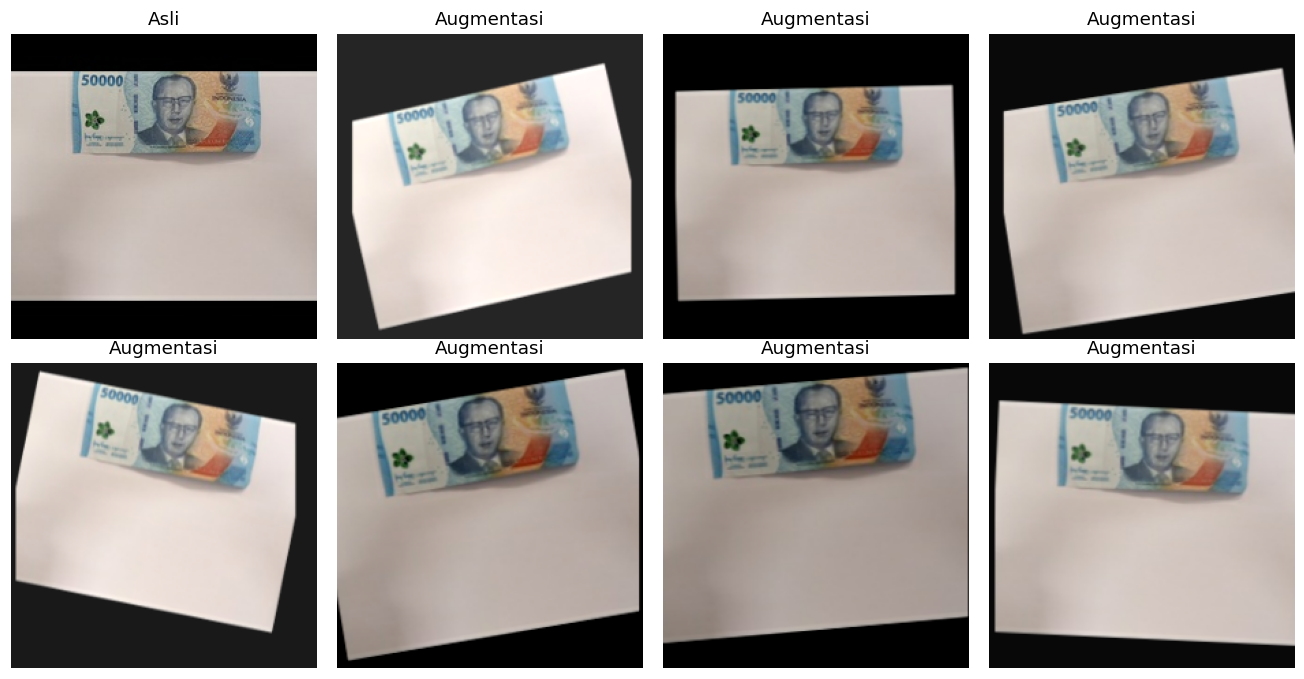

In [ ]:
def build_augmentation():
    return tf.keras.Sequential([
        layers.RandomRotation(0.05, fill_mode='constant', fill_value=0.0),
        layers.RandomZoom(0.10, fill_mode='constant', fill_value=0.0),
        layers.RandomTranslation(0.05, 0.05, fill_mode='constant', fill_value=0.0),
        layers.RandomContrast(0.15),
        layers.RandomBrightness(0.15, value_range=(0, 255)),
    ], name='augmentation_train_only')

# Pratinjau: satu gambar train diaugmentasi 7 kali
preview_aug = build_augmentation()
img0 = next(iter(train_ds.unbatch().take(1)))[0][None]
fig, axes = plt.subplots(2, 4, figsize=(12, 6.2))
axes[0, 0].imshow(img0[0].numpy().astype('uint8')); axes[0, 0].set_title('Asli')
for ax in axes.flat[1:]:
    ax.imshow(np.clip(preview_aug(img0, training=True)[0].numpy(), 0, 255).astype('uint8'))
    ax.set_title('Augmentasi')
for ax in axes.flat: ax.axis('off')
plt.tight_layout(); plt.show()

## 7. Custom CNN - baseline



In [ ]:
def conv_block(x, filters, l2):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding='same', use_bias=False, kernel_regularizer=regularizers.l2(l2))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
    return layers.MaxPooling2D()(x)


def build_custom_cnn(use_aug=False, filters=(32, 64, 128, 256), dense_units=128, dropout=0.4, l2=1e-4):
    inp = layers.Input(shape=(*IMG_SIZE, 3), name='rupiah_image')       # RGB float32 dalam [0, 255]
    x = build_augmentation()(inp) if use_aug else inp
    x = layers.Rescaling(1. / 255, name='rescale_0_1')(x)
    for f in filters:
        x = conv_block(x, f, l2)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation='relu', kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(len(CLASSES), activation='softmax', name='kelas')(x)
    return tf.keras.Model(inp, out, name='rupiah_custom_cnn')


def compile_model(model, lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='sparse_categorical_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(2, name='top2')])
    return model


build_custom_cnn().summary(line_length=100)

Model: "rupiah_custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ rupiah_image (InputLayer)                  │ (None, 224, 224, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ rescale_0_1 (Rescaling)                    │ (None, 224, 224, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d (Conv2D)                            │ (None, 224, 224, 32)            │               864 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ batch_normalization (BatchNormalization)   │ (None, 224, 224, 32)            │               128 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ activation (Activation)                    │ (None, 224, 224, 32)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d_1 (Conv2D)                          │ (None, 224, 224, 32)            │             9,216 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ batch_normalization_1 (BatchNormalization) │ (None, 224, 224, 32)            │               128 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ activation_1 (Activation)                  │ (None, 224, 224, 32)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ max_pooling2d (MaxPooling2D)               │ (None, 112, 112, 32)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d_2 (Conv2D)                          │ (None, 112, 112, 64)            │            18,432 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ batch_normalization_2 (BatchNormalization) │ (None, 112, 112, 64)            │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ activation_2 (Activation)                  │ (None, 112, 112, 64)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d_3 (Conv2D)                          │ (None, 112, 112, 64)            │            36,864 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ batch_normalization_3 (BatchNormalization) │ (None, 112, 112, 64)            │               256 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ activation_3 (Activation)                  │ (None, 112, 112, 64)            │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ max_pooling2d_1 (MaxPooling2D)             │ (None, 56, 56, 64)              │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv2d_4 (Conv2D)                          │ (None, 56, 56, 128)             │            73,728 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ batch_normalization_4 (BatchNormalization) │ (None, 56, 56, 128)             │               512 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ activation_4 (Activation)                  │ (None, 56, 56,

 Total params: 1,208,935 (4.61 MB)

 Trainable params: 1,207,015 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report


def wilson_ci(k, n, z=1.96):
    """Interval kepercayaan 95% (Wilson) untuk proporsi k/n."""
    p = k / n
    denom = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return centre - half, centre + half


def plot_history(history_df, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, m in zip(axes, ['accuracy', 'loss']):
        ax.plot(history_df.index + 1, history_df[m], label='train')
        ax.plot(history_df.index + 1, history_df['val_' + m], label='validation')
        ax.set(xlabel='Epoch', ylabel=m, title=f'{title} - {m}'); ax.legend()
    plt.tight_layout(); fig.savefig(RESULTS / filename, dpi=160); plt.show()


def train_experiment(name, title, use_aug, epochs, lr, early_stop):
    """Latih satu konfigurasi dari bobot acak dan simpan model, riwayat, dan kurva."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = compile_model(build_custom_cnn(use_aug=use_aug), lr)
    cbs = [tf.keras.callbacks.TerminateOnNaN()]
    if early_stop:
        cbs += [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=cfg.patience, restore_best_weights=True),
                tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=max(2, cfg.patience // 3), min_lr=1e-6)]
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=cbs, verbose=2, shuffle=False,
                     class_weight=CLASS_WEIGHT if USE_CLASS_WEIGHT else None)
    secs = time.time() - t0
    hdf = pd.DataFrame(hist.history)
    hdf.to_csv(RESULTS / f'{name}_history.csv', index=False)
    plot_history(hdf, title, f'{name}_accuracy_loss.png')
    v_loss, v_acc, v_top2 = model.evaluate(val_ds, verbose=0)
    n_val = len(val_paths)
    lo, hi = wilson_ci(round(v_acc * n_val), n_val)
    model.save(RESULTS / f'{name}.keras')
    return {'name': name, 'model': model, 'augmentation': use_aug, 'epochs_ran': len(hdf),
            'best_epoch': int(hdf.val_loss.idxmin()) + 1, 'params': model.count_params(),
            'val_accuracy': float(v_acc), 'val_ci_low': lo, 'val_ci_high': hi,
            'val_top2': float(v_top2), 'val_loss': float(v_loss), 'train_seconds': round(secs, 1)}


def predict_split(model, ds):
    y_true = np.concatenate([y.numpy() for _, y in ds])
    probs = model.predict(ds, verbose=0)
    return y_true, probs


def evaluate_and_save(model, ds, paths, prefix, title):
    """Confusion matrix (jumlah & ternormalisasi), laporan per kelas, dan prediksi per gambar."""
    y_true, probs = predict_split(model, ds)
    y_pred = probs.argmax(1)
    labels = list(range(len(CLASSES)))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    rep = classification_report(y_true, y_pred, labels=labels, target_names=CLASSES, output_dict=True, zero_division=0)
    pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(RESULTS / f'{prefix}_confusion_matrix.csv')
    pd.DataFrame(rep).T.to_csv(RESULTS / f'{prefix}_classification_report.csv')
    pred_df = pd.DataFrame({'path': paths, 'true': [CLASSES[i] for i in y_true], 'pred': [CLASSES[i] for i in y_pred],
                            'confidence': probs.max(1), 'correct': y_true == y_pred})
    pred_df.to_csv(RESULTS / f'{prefix}_predictions.csv', index=False)

    names = [pretty(c) for c in CLASSES]
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, mat, fmt, sub in ((axes[0], cm, 'd', 'jumlah gambar'), (axes[1], cm_norm, '.2f', 'dinormalisasi per baris (recall)')):
        im = ax.imshow(mat, cmap='Blues'); ax.grid(False)
        ax.set_xticks(labels, names, rotation=45, ha='right'); ax.set_yticks(labels, names)
        for i in labels:
            for j in labels:
                ax.text(j, i, format(mat[i, j], fmt), ha='center', va='center',
                        color='white' if mat[i, j] > mat.max() / 2 else 'black', fontsize=9)
        ax.set(title=f'{title} - {sub}', xlabel='Prediksi', ylabel='Sebenarnya')
    plt.tight_layout(); fig.savefig(RESULTS / f'{prefix}_confusion_matrix.png', dpi=160); plt.show()

    per_class = pd.DataFrame(rep).T.loc[CLASSES, ['precision', 'recall', 'f1-score', 'support']].round(3)
    per_class.index = names
    display(per_class)
    print(f'Accuracy = {(y_true == y_pred).mean():.4f} | Macro-F1 = {rep["macro avg"]["f1-score"]:.4f}')
    return {'y_true': y_true, 'y_pred': y_pred, 'probs': probs, 'cm': cm, 'report': rep, 'pred_df': pred_df}

Epoch 1/15
28/28 - 59s - 2s/step - accuracy: 0.5515 - loss: 1.3299 - top2: 0.7539 - val_accuracy: 0.0852 - val_loss: 2.4159 - val_top2: 0.2557
Epoch 2/15
28/28 - 5s - 178ms/step - accuracy: 0.8680 - loss: 0.5916 - top2: 0.9631 - val_accuracy: 0.1932 - val_loss: 3.6976 - val_top2: 0.2557
Epoch 3/15
28/28 - 5s - 178ms/step - accuracy: 0.9094 - loss: 0.4167 - top2: 0.9810 - val_accuracy: 0.0852 - val_loss: 5.7801 - val_top2: 0.2557
Epoch 4/15
28/28 - 5s - 178ms/step - accuracy: 0.9430 - loss: 0.3325 - top2: 0.9888 - val_accuracy: 0.0852 - val_loss: 3.5419 - val_top2: 0.2557
Epoch 5/15
28/28 - 5s - 180ms/step - accuracy: 0.9720 - loss: 0.2281 - top2: 0.9955 - val_accuracy: 0.0852 - val_loss: 6.7699 - val_top2: 0.2557
Epoch 6/15
28/28 - 5s - 181ms/step - accuracy: 0.9642 - loss: 0.2147 - top2: 0.9978 - val_accuracy: 0.1648 - val_loss: 5.9232 - val_top2: 0.3125
Epoch 7/15
28/28 - 5s - 182ms/step - accuracy: 0.9743 - loss: 0.2223 - top2: 0.9933 - val_accuracy: 0.0852 - val_loss: 9.8381 - val_

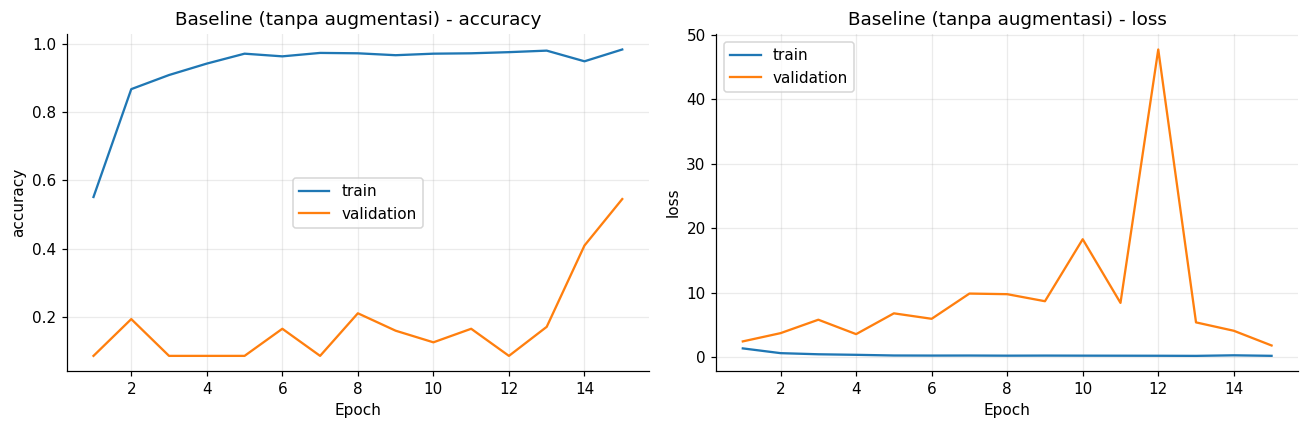


BASELINE validation: loss=1.7819 | accuracy=54.55% (95% CI 47.2%-61.7%) | top-2=70.45%


In [ ]:
BASE_EPOCHS = 1 if cfg.quick_test else cfg.baseline_epochs
TUNE_EPOCHS = 2 if cfg.quick_test else cfg.tuning_epochs

baseline = train_experiment('baseline_no_aug', 'Baseline (tanpa augmentasi)', use_aug=False,
                            epochs=BASE_EPOCHS, lr=cfg.baseline_lr, early_stop=False)
print(f"\nBASELINE validation: loss={baseline['val_loss']:.4f} | accuracy={baseline['val_accuracy']:.2%} "
      f"(95% CI {baseline['val_ci_low']:.1%}-{baseline['val_ci_high']:.1%}) | top-2={baseline['val_top2']:.2%}")

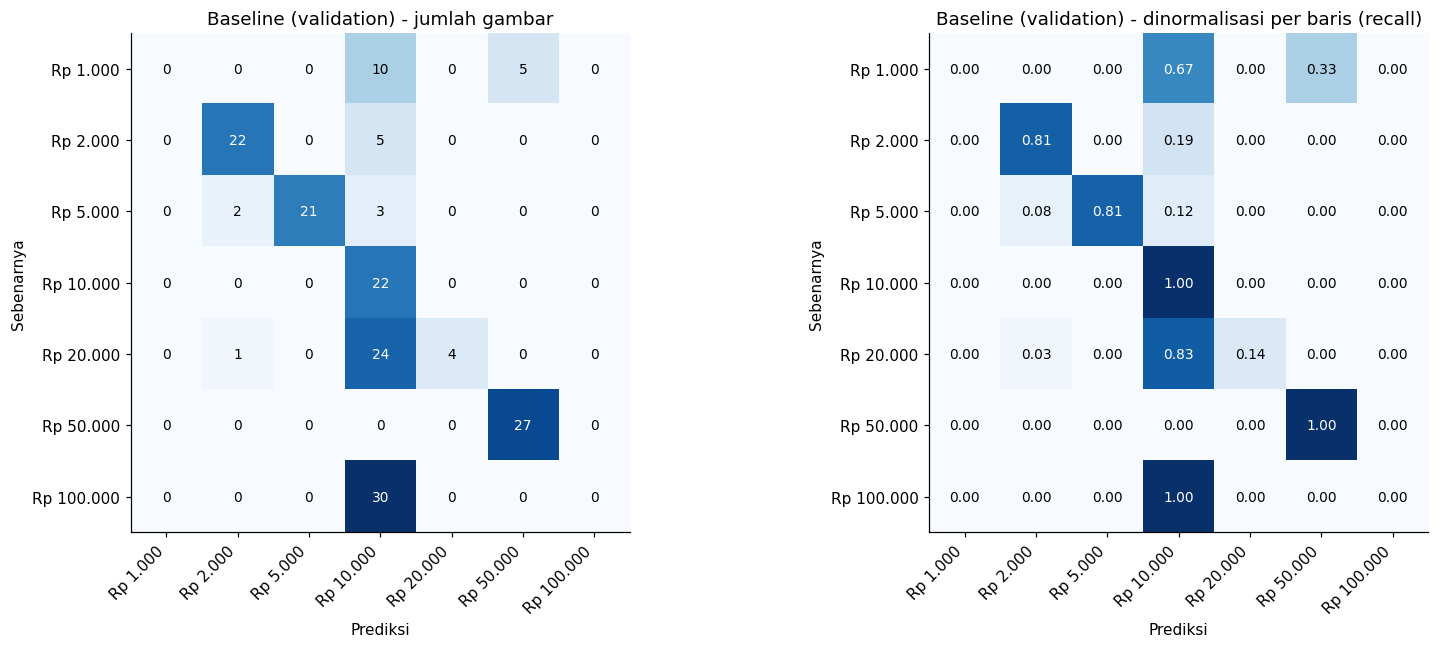

,precision,recall,f1-score,support
Rp 1.000,0.000,0.000,0.000,15.0
Rp 2.000,0.880,0.815,0.846,27.0
Rp 5.000,1.000,0.808,0.894,26.0
Rp 10.000,0.234,1.000,0.379,22.0
Rp 20.000,1.000,0.138,0.242,29.0
Rp 50.000,0.844,1.000,0.915,27.0
Rp 100.000,0.000,0.000,0.000,30.0


Accuracy = 0.5455 | Macro-F1 = 0.4681


In [ ]:
# Confusion matrix baseline memakai VALIDATION agar test set tetap bersih untuk evaluasi final
baseline_eval = evaluate_and_save(baseline['model'], val_ds, val_paths, 'baseline_validation', 'Baseline (validation)')

## 8. Tuning Custom CNN - epoch dan augmentasi



===== EKSPERIMEN: tuned_no_aug =====
Epoch 1/30
28/28 - 22s - 787ms/step - accuracy: 0.5872 - loss: 1.2527 - top2: 0.7796 - val_accuracy: 0.1705 - val_loss: 2.1342 - val_top2: 0.2557 - learning_rate: 5.0000e-04
Epoch 2/30
28/28 - 5s - 183ms/step - accuracy: 0.8937 - loss: 0.5643 - top2: 0.9709 - val_accuracy: 0.1705 - val_loss: 2.7510 - val_top2: 0.2557 - learning_rate: 5.0000e-04
Epoch 3/30
28/28 - 5s - 187ms/step - accuracy: 0.9463 - loss: 0.3572 - top2: 0.9899 - val_accuracy: 0.1705 - val_loss: 2.6149 - val_top2: 0.2670 - learning_rate: 5.0000e-04
Epoch 4/30
28/28 - 5s - 190ms/step - accuracy: 0.9642 - loss: 0.2509 - top2: 0.9978 - val_accuracy: 0.1705 - val_loss: 2.4390 - val_top2: 0.3352 - learning_rate: 2.5000e-04
Epoch 5/30
28/28 - 5s - 194ms/step - accuracy: 0.9855 - loss: 0.1917 - top2: 0.9989 - val_accuracy: 0.1307 - val_loss: 2.3583 - val_top2: 0.3068 - learning_rate: 2.5000e-04
Epoch 6/30
28/28 - 6s - 199ms/step - accuracy: 0.9832 - loss: 0.1837 - top2: 0.9966 - val_accura

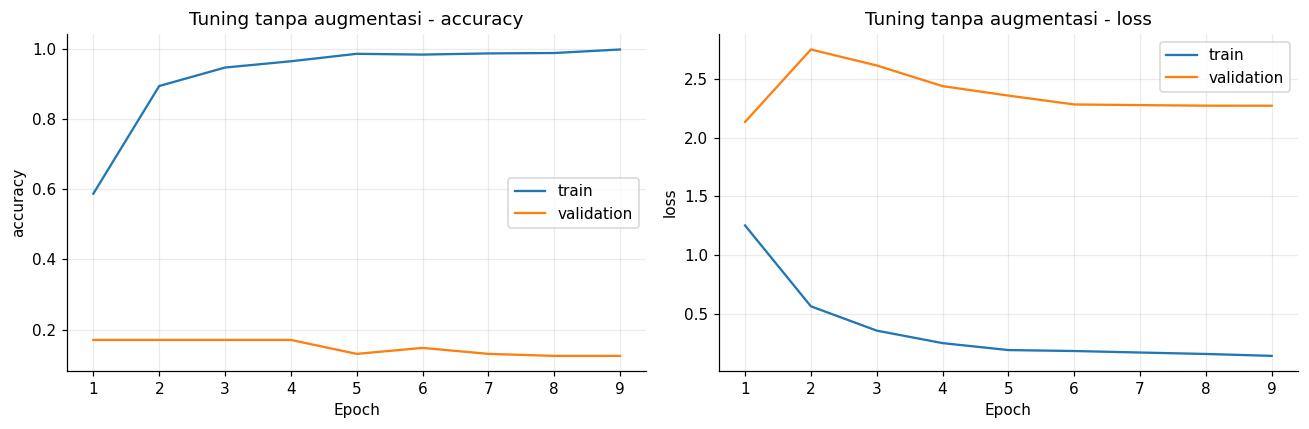


===== EKSPERIMEN: tuned_with_aug =====
Epoch 1/30
28/28 - 29s - 1s/step - accuracy: 0.4139 - loss: 1.5961 - top2: 0.6353 - val_accuracy: 0.0852 - val_loss: 2.0721 - val_top2: 0.2500 - learning_rate: 5.0000e-04
Epoch 2/30
28/28 - 9s - 312ms/step - accuracy: 0.7260 - loss: 0.9440 - top2: 0.9060 - val_accuracy: 0.1477 - val_loss: 2.2346 - val_top2: 0.2102 - learning_rate: 5.0000e-04
Epoch 3/30
28/28 - 9s - 314ms/step - accuracy: 0.8512 - loss: 0.6193 - top2: 0.9564 - val_accuracy: 0.1420 - val_loss: 2.0886 - val_top2: 0.2102 - learning_rate: 5.0000e-04
Epoch 4/30
28/28 - 9s - 314ms/step - accuracy: 0.9273 - loss: 0.4134 - top2: 0.9765 - val_accuracy: 0.0852 - val_loss: 2.2739 - val_top2: 0.2102 - learning_rate: 2.5000e-04
Epoch 5/30
28/28 - 9s - 313ms/step - accuracy: 0.9351 - loss: 0.3558 - top2: 0.9821 - val_accuracy: 0.0852 - val_loss: 2.2451 - val_top2: 0.2102 - learning_rate: 2.5000e-04
Epoch 6/30
28/28 - 9s - 310ms/step - accuracy: 0.9519 - loss: 0.2969 - top2: 0.9922 - val_accurac

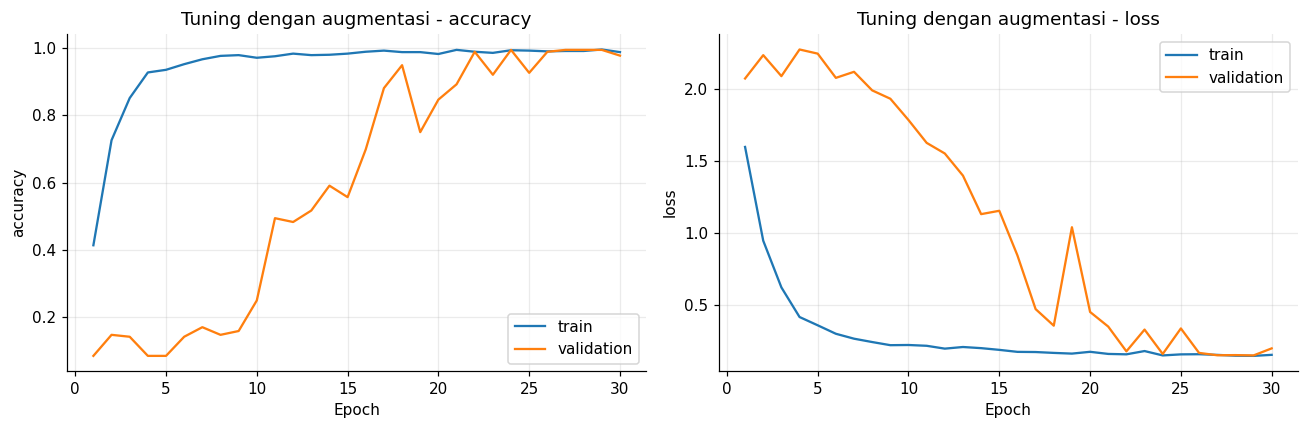

In [ ]:
runs = {'baseline_no_aug': baseline}
for name, title, aug in [('tuned_no_aug', 'Tuning tanpa augmentasi', False),
                         ('tuned_with_aug', 'Tuning dengan augmentasi', True)]:
    print(f'\n===== EKSPERIMEN: {name} =====')
    runs[name] = train_experiment(name, title, use_aug=aug, epochs=TUNE_EPOCHS, lr=cfg.tuning_lr, early_stop=True)

,name,augmentation,epochs_ran,best_epoch,params,val_accuracy,val_ci_low,val_ci_high,val_top2,val_loss,train_seconds
0,tuned_with_aug,True,30,29,1208935,0.9943,0.9685,0.9990,1.0000,0.1462,280.9
1,baseline_no_aug,False,15,15,1208935,0.5455,0.4717,0.6173,0.7045,1.7819,131.6
2,tuned_no_aug,False,9,1,1208935,0.1705,0.1221,0.2329,0.2557,2.1342,65.4


Model terbaik menurut validation: tuned_with_aug


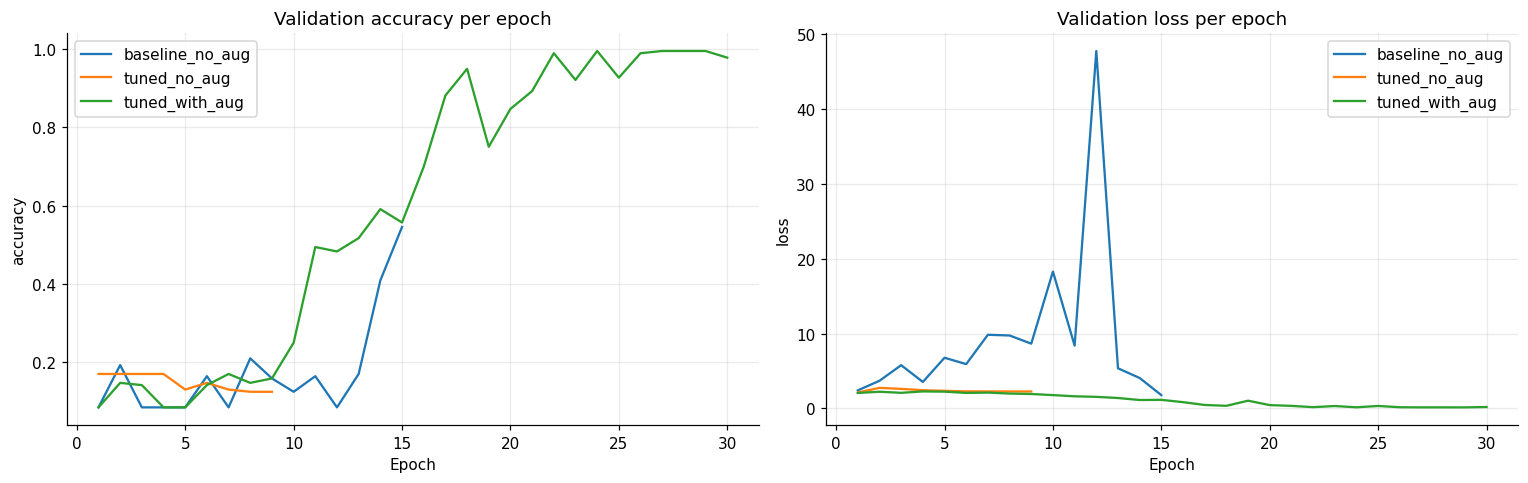

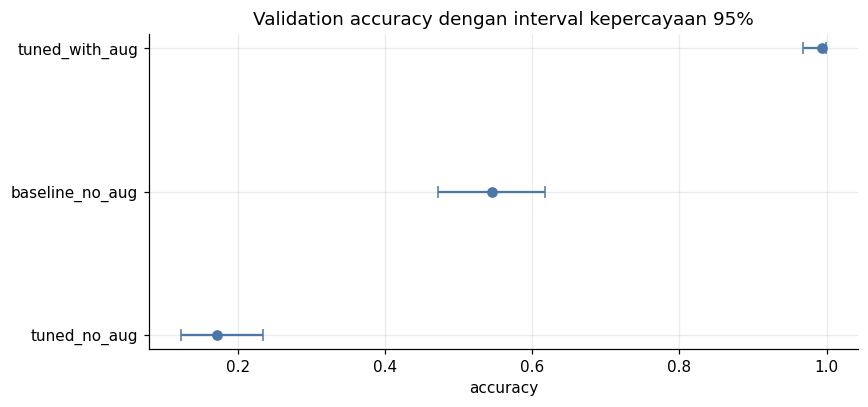

In [ ]:
cols = ['name', 'augmentation', 'epochs_ran', 'best_epoch', 'params', 'val_accuracy', 'val_ci_low', 'val_ci_high',
        'val_top2', 'val_loss', 'train_seconds']
compare = (pd.DataFrame([{k: r[k] for k in cols} for r in runs.values()])
           .sort_values(['val_accuracy', 'val_loss'], ascending=[False, True]).reset_index(drop=True))
compare.to_csv(RESULTS / 'experiment_comparison.csv', index=False)
display(compare.round(4))

best_name = compare.loc[0, 'name']
best_model = runs[best_name]['model']
print(f'Model terbaik menurut validation: {best_name}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name in runs:
    h = pd.read_csv(RESULTS / f'{name}_history.csv')
    axes[0].plot(h.index + 1, h.val_accuracy, label=name)
    axes[1].plot(h.index + 1, h.val_loss, label=name)
axes[0].set(title='Validation accuracy per epoch', xlabel='Epoch', ylabel='accuracy')
axes[1].set(title='Validation loss per epoch', xlabel='Epoch', ylabel='loss')
for ax in axes: ax.legend()
plt.tight_layout(); fig.savefig(RESULTS / 'experiment_curves.png', dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(compare))
ax.errorbar(compare.val_accuracy, y, xerr=[compare.val_accuracy - compare.val_ci_low, compare.val_ci_high - compare.val_accuracy],
            fmt='o', capsize=4, color='#4C78A8')
ax.set_yticks(y, compare.name); ax.invert_yaxis()
ax.set(title='Validation accuracy dengan interval kepercayaan 95%', xlabel='accuracy')
plt.tight_layout(); plt.show()

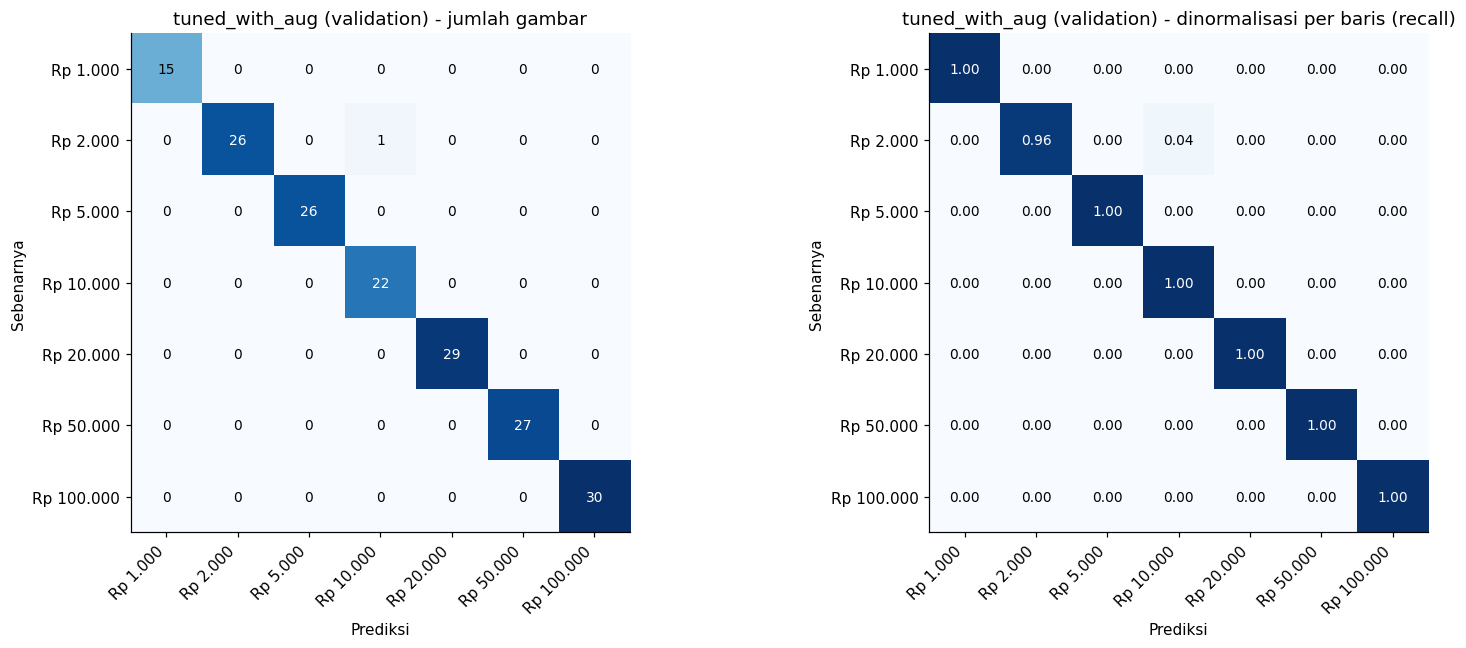

,precision,recall,f1-score,support
Rp 1.000,1.000,1.000,1.000,15.0
Rp 2.000,1.000,0.963,0.981,27.0
Rp 5.000,1.000,1.000,1.000,26.0
Rp 10.000,0.957,1.000,0.978,22.0
Rp 20.000,1.000,1.000,1.000,29.0
Rp 50.000,1.000,1.000,1.000,27.0
Rp 100.000,1.000,1.000,1.000,30.0


Accuracy = 0.9943 | Macro-F1 = 0.9941


In [ ]:
best_val_eval = evaluate_and_save(best_model, val_ds, val_paths, 'best_validation', f'{best_name} (validation)')

## 9. Evaluasi final pada test set




TEST (tuned_with_aug): accuracy=99.44% (95% CI 96.9%-99.9%) | top-2=100.00% | loss=0.1145 | n=179


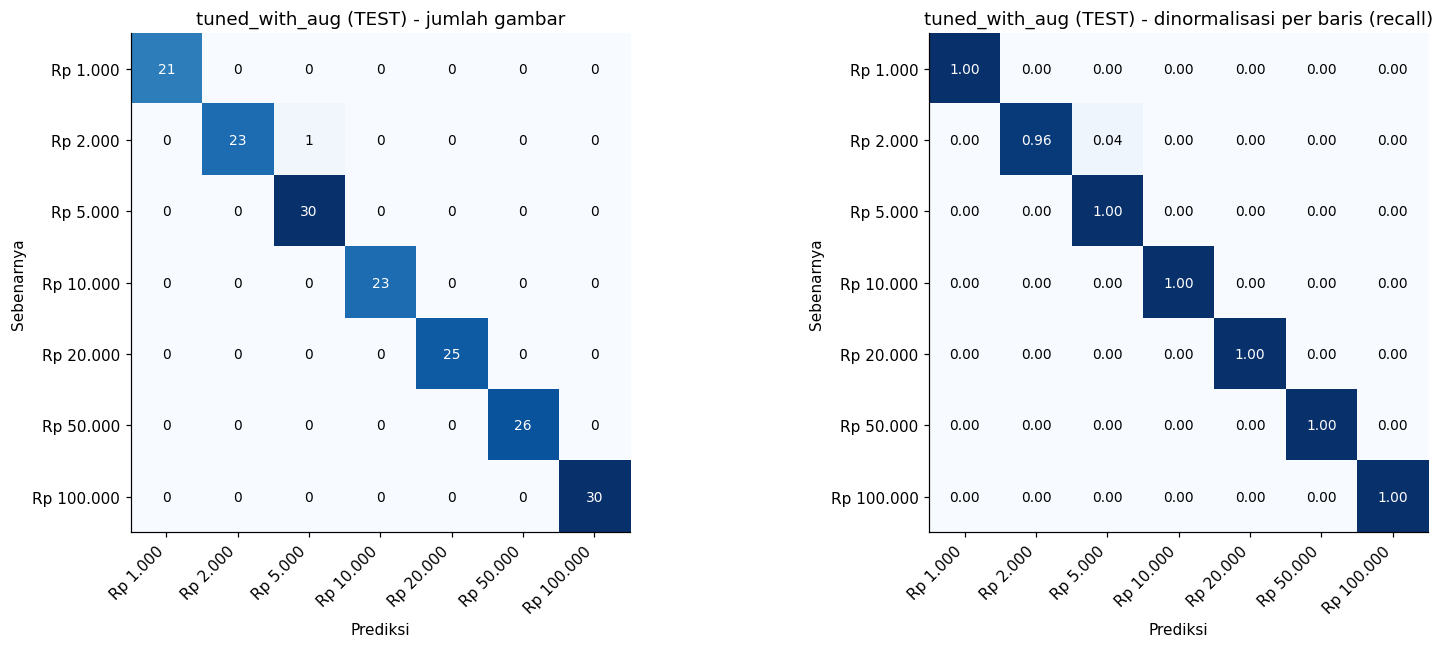

,precision,recall,f1-score,support
Rp 1.000,1.000,1.000,1.000,21.0
Rp 2.000,1.000,0.958,0.979,24.0
Rp 5.000,0.968,1.000,0.984,30.0
Rp 10.000,1.000,1.000,1.000,23.0
Rp 20.000,1.000,1.000,1.000,25.0
Rp 50.000,1.000,1.000,1.000,26.0
Rp 100.000,1.000,1.000,1.000,30.0


Accuracy = 0.9944 | Macro-F1 = 0.9946


In [ ]:
test_loss, test_acc, test_top2 = best_model.evaluate(test_ds, verbose=0)
n_test = len(test_paths)
t_lo, t_hi = wilson_ci(round(test_acc * n_test), n_test)
print(f'TEST ({best_name}): accuracy={test_acc:.2%} (95% CI {t_lo:.1%}-{t_hi:.1%}) | top-2={test_top2:.2%} | loss={test_loss:.4f} | n={n_test}')
test_eval = evaluate_and_save(best_model, test_ds, test_paths, 'final_test', f'{best_name} (TEST)')
best_model.save(RESULTS / 'custom_cnn_selected_final.keras')

Pasangan kelas yang paling sering tertukar (test):


,sebenarnya,diprediksi,jumlah
0,idr_2000,idr_5000,1


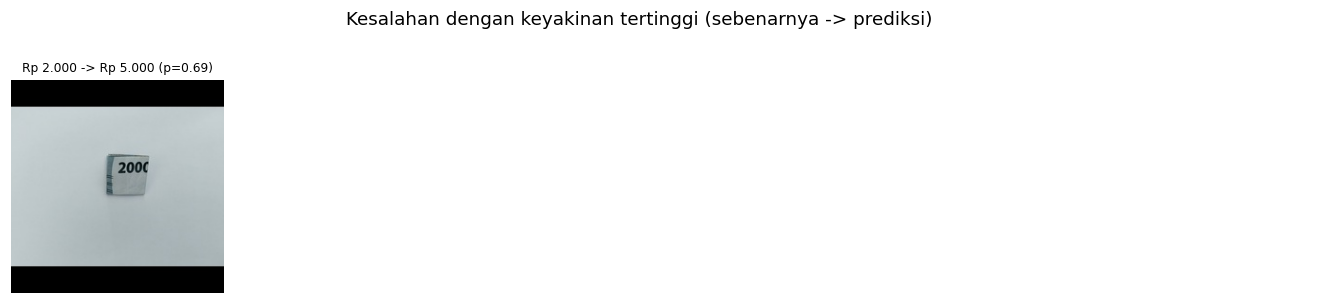

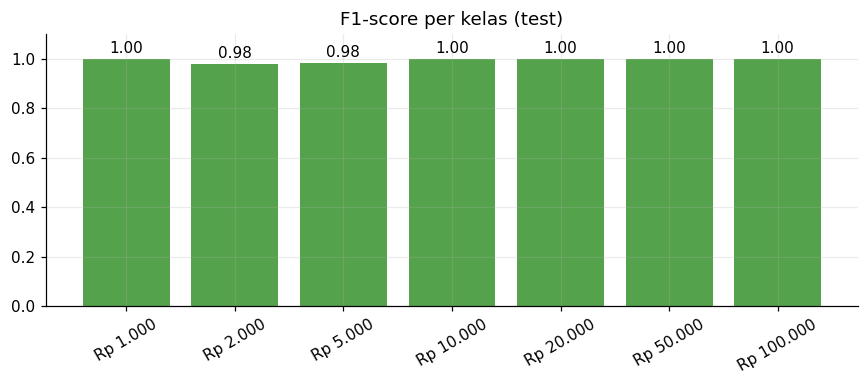

In [ ]:
yt, yp = test_eval['y_true'], test_eval['y_pred']
conf = [(CLASSES[i], CLASSES[j], int(test_eval['cm'][i, j])) for i in range(len(CLASSES)) for j in range(len(CLASSES))
        if i != j and test_eval['cm'][i, j] > 0]
conf_df = pd.DataFrame(conf, columns=['sebenarnya', 'diprediksi', 'jumlah']).sort_values('jumlah', ascending=False)
print('Pasangan kelas yang paling sering tertukar (test):')
display(conf_df.head(10) if len(conf_df) else 'Tidak ada kesalahan pada test set.')

wrong = test_eval['pred_df'][~test_eval['pred_df'].correct].sort_values('confidence', ascending=False).head(12)
if len(wrong):
    show_gallery(wrong.path.tolist(),
                 [f'{pretty(r.true)} -> {pretty(r.pred)} (p={r.confidence:.2f})' for r in wrong.itertuples()],
                 ncols=4, suptitle='Kesalahan dengan keyakinan tertinggi (sebenarnya -> prediksi)')

f1 = pd.Series({pretty(c): test_eval['report'][c]['f1-score'] for c in CLASSES})
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(f1.index, f1.values, color='#54A24B'); ax.bar_label(bars, fmt='%.2f', padding=2)
ax.set(title='F1-score per kelas (test)', ylim=(0, 1.1)); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); fig.savefig(RESULTS / 'final_test_f1_per_class.png', dpi=160); plt.show()

In [ ]:
summary = {
    'selected_model': best_name,
    'classes': CLASSES,
    'images': {'found': int(len(inventory)), 'valid': int(len(valid)), 'excluded_exact_or_conflict': int(len(excluded)),
               'unique_used': int(len(clean)), 'train': int((split_df.split == 'train').sum()),
               'validation': int((split_df.split == 'val').sum()), 'test': int((split_df.split == 'test').sum())},
    'near_duplicate': {'threshold': cfg.near_dup_threshold, 'groups': int(n_groups), 'multi_image_groups': int((sizes > 1).sum()),
                       'images_in_multi_image_groups': in_multi, 'cross_label_close_pairs': n_cross},
    'baseline_validation_accuracy': runs['baseline_no_aug']['val_accuracy'],
    'selected_validation_accuracy': float(compare.loc[0, 'val_accuracy']),
    'final_test': {'accuracy': float(test_acc), 'ci95': [t_lo, t_hi], 'top2': float(test_top2), 'loss': float(test_loss),
                   'macro_f1': float(test_eval['report']['macro avg']['f1-score'])},
    'class_weight_used': USE_CLASS_WEIGHT,
    'quick_test_mode': cfg.quick_test,
    'config': asdict(cfg),
    'environment': {'python': platform.python_version(), 'tensorflow': tf.__version__, 'numpy': np.__version__,
                    'pandas': pd.__version__, 'dataset_commit': DATASET_COMMIT},
}
(RESULTS / 'training_summary.json').write_text(json.dumps(summary, indent=2, default=str), encoding='utf-8')

report = f"""# Laporan Klasifikasi Uang Kertas Rupiah (Custom CNN)

{'**PERINGATAN: dibuat dalam mode uji cepat; angka tidak valid.**' if cfg.quick_test else ''}

## Data
- Dataset: mkaspulanwar/rupiah-banknotes-dataset (commit `{DATASET_COMMIT[:10] if len(DATASET_COMMIT) == 40 else DATASET_COMMIT}`)
- Gambar ditemukan / valid: {len(inventory)} / {len(valid)}
- Dikeluarkan (duplikat persis / label konflik): {len(excluded)}
- Gambar unik dipakai: {len(clean)}
- Near-duplicate: {int((sizes > 1).sum())} group berisi >1 gambar ({in_multi} gambar); group dijaga utuh pada satu split
- Split (stratified + group-aware): train {summary['images']['train']}, val {summary['images']['validation']}, test {summary['images']['test']}
- Ukuran input: {IMG_SIZE[0]}x{IMG_SIZE[1]} (mode `{cfg.resize_mode}`), normalisasi 1/255 di dalam model
- Class weight: {'dipakai' if USE_CLASS_WEIGHT else 'tidak dipakai (rasio kelas ' + format(imbalance, '.2f') + ')'}

## Eksperimen (validation)
```
{compare[['name', 'augmentation', 'epochs_ran', 'val_accuracy', 'val_ci_low', 'val_ci_high', 'val_loss']].round(4).to_string(index=False)}
```

Model terpilih: **{best_name}**

## Hasil akhir (test, n={n_test})
- Accuracy: **{test_acc:.2%}** (95% CI {t_lo:.1%} - {t_hi:.1%})
- Top-2 accuracy: {test_top2:.2%}
- Macro-F1: {test_eval['report']['macro avg']['f1-score']:.3f}

## Batasan
- Dataset kecil dan dari satu sumber; near-duplicate hanya terdeteksi lewat dHash, sehingga foto sesi sama dengan pose berbeda masih mungkin ada di split berbeda dan membuat akurasi sedikit optimistis.
- Interval kepercayaan lebar karena test set kecil.
- Folder `idr_mix` dan `test` pada repo belum dipakai; keduanya kandidat evaluasi eksternal setelah labelnya diverifikasi.
- Model dilatih dari nol; transfer learning (misalnya MobileNetV2) layak dibandingkan sebagai langkah berikutnya.
"""
(RESULTS / 'final_report.md').write_text(report, encoding='utf-8')
print(report)

archive = shutil.make_archive(str(OUT_ROOT), 'zip', root_dir=OUT_ROOT.parent, base_dir=OUT_ROOT.name)
print('ZIP:', archive, f'({Path(archive).stat().st_size / 1024 ** 2:.1f} MB)')
# Colab - unduh langsung atau salin ke Drive:
# from google.colab import files; files.download(archive)
# from google.colab import drive; drive.mount('/content/drive'); shutil.copy2(archive, '/content/drive/MyDrive/')

# Laporan Klasifikasi Uang Kertas Rupiah (Custom CNN)



## Data
- Dataset: mkaspulanwar/rupiah-banknotes-dataset (commit `8574bfae07`)
- Gambar ditemukan / valid: 1249 / 1249
- Dikeluarkan (duplikat persis / label konflik): 0
- Gambar unik dipakai: 1249
- Near-duplicate: 64 group berisi >1 gambar (187 gambar); group dijaga utuh pada satu split
- Split (stratified + group-aware): train 894, val 176, test 179
- Ukuran input: 224x224 (mode `pad`), normalisasi 1/255 di dalam model
- Class weight: tidak dipakai (rasio kelas 1.34)

## Eksperimen (validation)
```
           name  augmentation  epochs_ran  val_accuracy  val_ci_low  val_ci_high  val_loss
 tuned_with_aug          True          30        0.9943      0.9685       0.9990    0.1462
baseline_no_aug         False          15        0.5455      0.4717       0.6173    1.7819
   tuned_no_aug         False           9        0.1705      0.1221       0.2329    2.1342
```

Model terpilih: **tuned_with_aug**

## Hasil akhir (test, n=179)
- 